## 1. Environment Setup


In [ ]:
# Check environment and setup folders
import os
import sys

IS_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IS_COLAB:
    BASE_DIR   = "/content/curalm_project"
    CACHE_DIR  = "/content/curalm_cache"
    OUTPUT_DIR = "/content/curalm_output"
    PLOTS_DIR  = "/content/curalm_plots"
else:
    BASE_DIR   = os.path.join(os.getcwd(), "CURALM_output")
    CACHE_DIR  = os.path.join(BASE_DIR, "hf_cache")
    OUTPUT_DIR = os.path.join(BASE_DIR, "checkpoints")
    PLOTS_DIR  = os.path.join(BASE_DIR, "plots")

for d in [BASE_DIR, CACHE_DIR, OUTPUT_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

os.environ["HF_HOME"]            = CACHE_DIR
os.environ["TRANSFORMERS_CACHE"] = os.path.join(CACHE_DIR, "transformers")
os.environ["HF_DATASETS_CACHE"]  = os.path.join(CACHE_DIR, "datasets")

print(f"Environment: {'Google Colab' if IS_COLAB else 'Local'}")
print(f"Base dir:    {BASE_DIR}")
print(f"Plots dir:   {PLOTS_DIR}")


import zipfile

RESTORE_FROM_DRIVE = True
DRIVE_ZIP_PATH     = "/content/drive/MyDrive/all_content.zip"

if RESTORE_FROM_DRIVE and IS_COLAB:
    from google.colab import drive

    print("\nMounting Google Drive...")
    drive.mount("/content/drive")

    if os.path.exists(DRIVE_ZIP_PATH):
        print(f"Extracting {DRIVE_ZIP_PATH} -> /content ...")
        with zipfile.ZipFile(DRIVE_ZIP_PATH, "r") as z:
            z.extractall("/content")
        print("Extraction complete.")
    else:
        print(f"WARNING: ZIP not found at {DRIVE_ZIP_PATH}")
        print("Check DRIVE_ZIP_PATH or set RESTORE_FROM_DRIVE = False for a fresh run.")

        # Check important files
    critical = {
        "LoRA adapter": os.path.join(BASE_DIR, "qlora_full_adapter"),
        "RAG index":    os.path.join(BASE_DIR, "rag_index.faiss"),
        "RAG docs":     os.path.join(BASE_DIR, "rag_docs.pkl"),
        "Model report": os.path.join(BASE_DIR, "model_report.json"),
        "Plots dir":    PLOTS_DIR,
    }
    all_ok = True
    print("\nFile check:")
    for name, path in critical.items():
        exists = os.path.exists(path)
        status = "OK" if exists else "MISSING"
        if not exists:
            all_ok = False
        print(f"  {status:7s}  {name:15s}  ({path})")

    if all_ok:
        print("\nAll critical files restored. You can skip to Cell 24.")
    else:
        print("\nWARNING: Some files are missing — check your ZIP structure.")
else:
    print("Drive restore skipped.")

Environment: Google Colab
Base dir:    /content/curalm_project
Plots dir:   /content/curalm_plots

Mounting Google Drive...
Mounted at /content/drive
Extracting /content/drive/MyDrive/all_content.zip -> /content ...
Extraction complete.

File check:
  MISSING  LoRA adapter     (/content/curalm_project/qlora_full_adapter)
  MISSING  RAG index        (/content/curalm_project/rag_index.faiss)
  MISSING  RAG docs         (/content/curalm_project/rag_docs.pkl)
  OK       Model report     (/content/curalm_project/model_report.json)
  OK       Plots dir        (/content/curalm_plots)



In [ ]:
# Install Dependencies and required packages
import subprocess
subprocess.check_call([
    sys.executable, "-m", "pip", "-q", "install", "-U",
    "transformers", "accelerate", "bitsandbytes", "peft", "trl",
    "sentencepiece", "safetensors", "datasets", "kagglehub",
    "scikit-learn", "matplotlib", "seaborn"
])
print(" All dependencies installed.")



 All dependencies installed.


## 2. GPU Detection & Model Configuration


In [ ]:
# Check GPU and set plot style

import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Simple plot style
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
})

# Make sure GPU is available
if not torch.cuda.is_available():
    raise RuntimeError("GPU is not available. Please enable GPU runtime.")

# Get GPU information
gpu_name = torch.cuda.get_device_name(0)
gpu_info = torch.cuda.get_device_properties(0)
gpu_memory = gpu_info.total_memory / (1024**3)

# Choose the best data type for training
gpu_major, gpu_minor = torch.cuda.get_device_capability(0)

use_bf16 = gpu_major >= 8
train_dtype = torch.bfloat16 if use_bf16 else torch.float16

print("GPU:", gpu_name)
print("CUDA Capability:", f"{gpu_major}.{gpu_minor}")
print("GPU Memory:", f"{gpu_memory:.1f} GB")
print("Training dtype:", train_dtype)
print("BF16 supported:", use_bf16)

GPU: NVIDIA H100 80GB HBM3
CUDA Capability: 9.0
GPU Memory: 79.2 GB
Training dtype: torch.bfloat16
BF16 supported: True


## 3. Load Base Model with 4-bit Quantization


In [ ]:
# Load model and tokenizer

from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

model_name = "BioMistral/BioMistral-7B-DARE"

# Use 4-bit loading to save GPU memory
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=train_dtype,
)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)

# Add padding token if missing
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load model
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quant_config,
    device_map="auto",
)

model.eval()

print("Model loaded:", model_name)
print("Vocab size:", len(tokenizer))

config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Model loaded: BioMistral/BioMistral-7B-DARE
Vocab size: 32000


In [ ]:
# Cell 5: Quick Pre-Training Test
question = "What are the side effects of doxycycline?"
prompt = f"[INST] You are a helpful medical AI assistant. {question} [/INST]"

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
    )

response = tokenizer.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(" Pre-training baseline response:")
print(response[:500])



 Pre-training baseline response:
Doxycycline is a broad-spectrum antibiotic that is commonly used to treat various bacterial infections. Like all medications, doxycycline can cause side effects. Some of the most common side effects of doxycycline include:

1. Nausea and vomiting
2. Diarrhea
3. Abdominal pain
4. Headache
5. Dizziness
6. Dry mouth
7. Skin rash
8. Itching
9. Swelling of the face, throat, or tongue
10. Difficulty breathing or swallowing

These side effects are usually mild and temporary, and they typically go away 


## 4. QLoRA Configuration


In [ ]:
# Prepare model for QLoRA training

from peft import prepare_model_for_kbit_training, LoraConfig, get_peft_model

# Prepare the model for 4-bit training
model = prepare_model_for_kbit_training(model)

# LoRA settings
lora_settings = LoraConfig(
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)

# Add LoRA to the model
model = get_peft_model(model, lora_settings)

# Show trainable parameters
model.print_trainable_parameters()

trainable params: 83,886,080 || all params: 7,325,618,176 || trainable%: 1.1451


## 5. Dataset Download & Exploratory Data Analysis


In [ ]:
# Download and load dataset

import kagglehub
import pandas as pd
import numpy as np
import glob
import os

# Download dataset from Kaggle
data_path = kagglehub.dataset_download("jithinanievarghese/drugs-side-effects-and-medical-condition")

print("Dataset path:", data_path)
print("Files:", os.listdir(data_path))

# Get all CSV files inside the dataset folder

csv_list = glob.glob(os.path.join(data_path, "*.csv"))


data = pd.read_csv(csv_list[0])

# Show basic info about dataset
print("\nDataset shape:", data.shape)
print("Columns:", data.columns.tolist())


data.head()

100%|██████████| 1.17M/1.17M [00:00<00:00, 137MB/s]

Extracting files...
Dataset path: /root/.cache/kagglehub/datasets/jithinanievarghese/drugs-side-effects-and-medical-condition/versions/1
Files: ['drugs_side_effects_drugs_com.csv']

Dataset shape: (2931, 17)
Columns: ['drug_name', 'medical_condition', 'side_effects', 'generic_name', 'drug_classes', 'brand_names', 'activity', 'rx_otc', 'pregnancy_category', 'csa', 'alcohol', 'related_drugs', 'medical_condition_description', 'rating', 'no_of_reviews', 'drug_link', 'medical_condition_url']


,drug_name,medical_condition,side_effects,generic_name,drug_classes,brand_names,activity,rx_otc,pregnancy_category,csa,alcohol,related_drugs,medical_condition_description,rating,no_of_reviews,drug_link,medical_condition_url
0,doxycycline,Acne,"(hives, difficult breathing, swelling in your ...",doxycycline,"Miscellaneous antimalarials, Tetracyclines","Acticlate, Adoxa CK, Adoxa Pak, Adoxa TT, Alod...",87%,Rx,D,N,X,amoxicillin: https://www.drugs.com/amoxicillin...,Acne Other names: Acne Vulgaris; Blackheads; B...,6.8,760.0,https://www.drugs.com/doxycycline.html,https://www.drugs.com/condition/acne.html
1,spironolactone,Acne,hives ; difficulty breathing; swelling of your...,spironolactone,"Aldosterone receptor antagonists, Potassium-sp...","Aldactone, CaroSpir",82%,Rx,C,N,X,amlodipine: https://www.drugs.com/amlodipine.h...,Acne Other names: Acne Vulgaris; Blackheads; B...,7.2,449.0,https://www.drugs.com/spironolactone.html,https://www.drugs.com/condition/acne.html
2,minocycline,Acne,"skin rash, fever, swollen glands, flu-like sym...",minocycline,Tetracyclines,"Dynacin, Minocin, Minolira, Solodyn, Ximino, V...",48%,Rx,D,N,NaN,amoxicillin: https://www.drugs.com/amoxicillin...,Acne Other names: Acne Vulgaris; Blackheads; B...,5.7,482.0,https://www.drugs.com/minocycline.html,https://www.drugs.com/condition/acne.html
3,Accutane,Acne,problems with your vision or hearing; muscle o...,isotretinoin (oral),"Miscellaneous antineoplastics, Miscellaneous u...",NaN,41%,Rx,X,N,X,doxycycline: https://www.drugs.com/doxycycline...,Acne Other names: Acne Vulgaris; Blackheads; B...,7.9,623.0,https://www.drugs.com/accutane.html,https://www.drugs.com/condition/acne.html
4,clindamycin,Acne,hives ; difficult breathing; swelling of your ...,clindamycin topical,"Topical acne agents, Vaginal anti-infectives","Cleocin T, Clindacin ETZ, Clindacin P, Clindag...",39%,Rx,B,N,NaN,doxycycline: https://www.drugs.com/doxycycline...,Acne Other names: Acne Vulgaris; Blackheads; B...,7.4,146.0,https://www.drugs.com/mtm/clindamycin-topical....,https://www.drugs.com/condition/acne.html


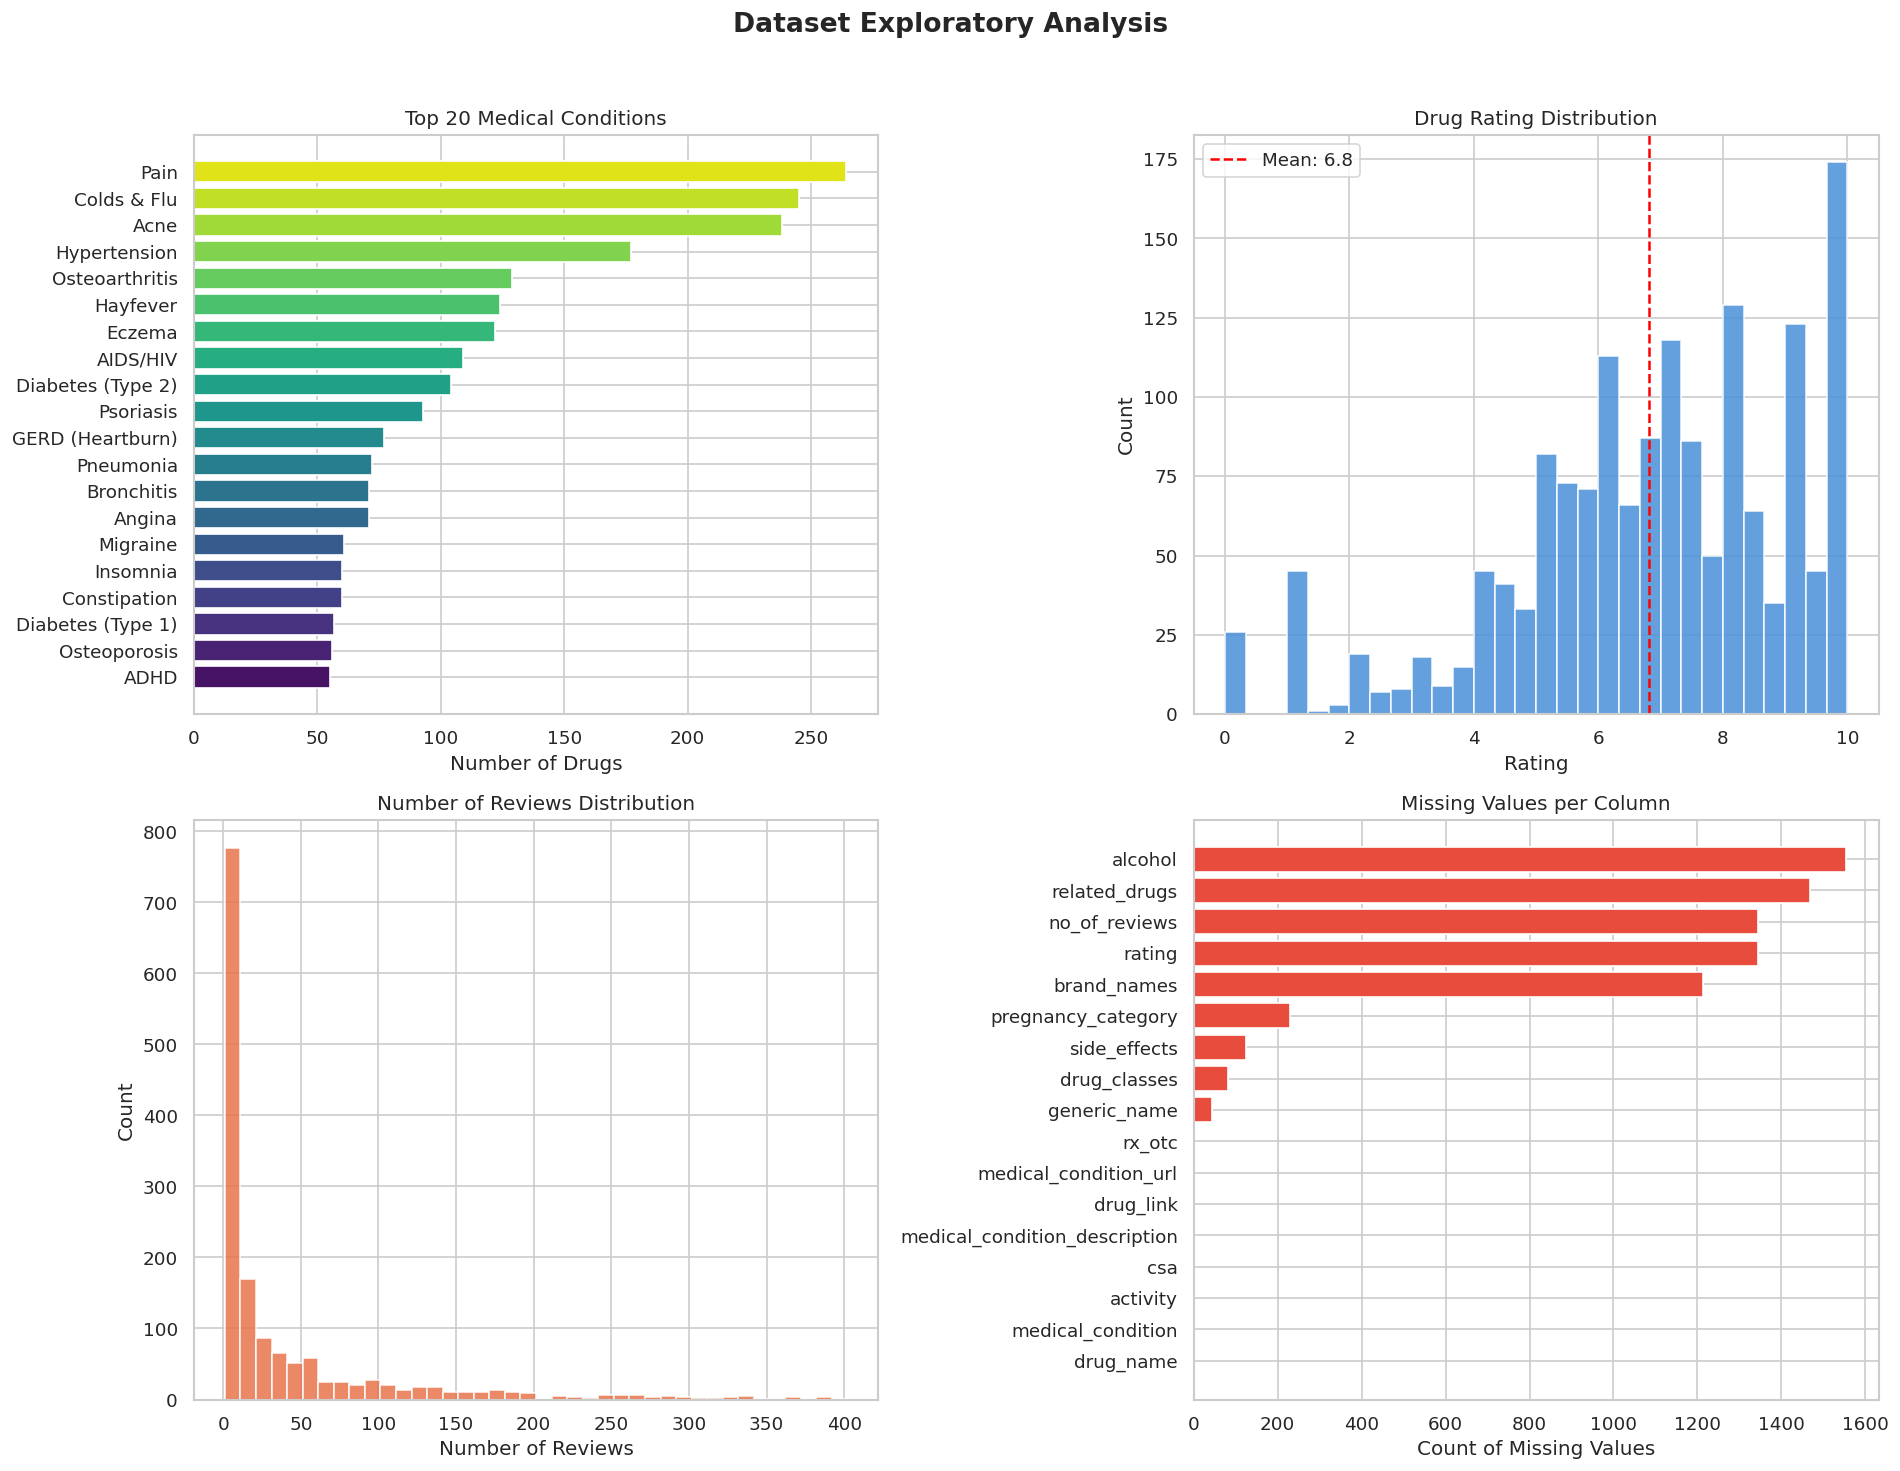

Saved: /content/curalm_plots/01_dataset_eda.png


In [ ]:
# Dataset visualizations
# This part helps us understand the dataset before training.

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make sure df exists
# If the dataset was saved as "data", use it as df
if "df" not in globals():
    if "data" in globals():
        df = data
    else:
        raise NameError("Dataset not found. Please run the dataset loading cell first.")

# Make sure plots folder exists
if "PLOTS_DIR" not in globals():
    if "plots_folder" in globals():
        PLOTS_DIR = plots_folder
    else:
        PLOTS_DIR = "."

fig, charts = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Dataset Exploratory Analysis", fontsize=16, fontweight="bold", y=1.02)


# Chart 1: Show the most common medical conditions
top_conditions = df["medical_condition"].value_counts().head(20)

charts[0, 0].barh(
    top_conditions.index[::-1],
    top_conditions.values[::-1],
    color=sns.color_palette("viridis", 20)
)

charts[0, 0].set_title("Top 20 Medical Conditions")
charts[0, 0].set_xlabel("Number of Drugs")


# Chart 2: Show drug rating distribution
if "rating" in df.columns:
    ratings = pd.to_numeric(df["rating"], errors="coerce").dropna()

    charts[0, 1].hist(
        ratings,
        bins=30,
        color="#4A90D9",
        edgecolor="white",
        alpha=0.85
    )

    charts[0, 1].set_title("Drug Rating Distribution")
    charts[0, 1].set_xlabel("Rating")
    charts[0, 1].set_ylabel("Count")

    # Average rating line
    charts[0, 1].axvline(
        ratings.mean(),
        color="red",
        linestyle="--",
        label=f"Mean: {ratings.mean():.1f}"
    )

    charts[0, 1].legend()


# Chart 3: Show number of reviews
if "no_of_reviews" in df.columns:
    reviews = pd.to_numeric(df["no_of_reviews"], errors="coerce").dropna()

    # Keep normal values only to make the chart clear
    reviews = reviews[reviews <= reviews.quantile(0.95)]

    charts[1, 0].hist(
        reviews,
        bins=40,
        color="#E8734A",
        edgecolor="white",
        alpha=0.85
    )

    charts[1, 0].set_title("Number of Reviews Distribution")
    charts[1, 0].set_xlabel("Number of Reviews")
    charts[1, 0].set_ylabel("Count")


# Chart 4: Show missing values
missing_values = df.isnull().sum().sort_values(ascending=True)

# Green = complete column, red = column has missing values
bar_colors = [
    "#2ecc71" if value == 0 else "#e74c3c"
    for value in missing_values.values
]

charts[1, 1].barh(
    missing_values.index,
    missing_values.values,
    color=bar_colors
)

charts[1, 1].set_title("Missing Values per Column")
charts[1, 1].set_xlabel("Count of Missing Values")


# Save and show the figure
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "01_dataset_eda.png"))
plt.show()

print(f"Saved: {PLOTS_DIR}/01_dataset_eda.png")

## 6. Data Cleaning & Preparation


In [ ]:
# Clean and normalize dataset columns

import re
import numpy as np
import pandas as pd

# Make a copy so the original dataset stays unchanged
df = df.copy()

# Make column names simple and consistent
# Example: "Drug Name" -> "drug_name"
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[\s\-/]+", "_", regex=True)
)

# Select only the columns needed for this project
needed_columns = [
    "drug_name", "medical_condition", "side_effects",
    "generic_name", "activity", "rating", "no_of_reviews",
]

work_df = df[needed_columns].copy()


# Clean text values
def clean_text(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    # Remove links and extra spaces
    value = re.sub(r"https?://\S+", "", value)
    value = re.sub(r"www\.\S+", "", value)
    value = re.sub(r"[\n\r\t]+", " ", value)
    value = " ".join(value.split())

    # Treat empty or unknown values as missing
    if value.lower() in ("", "nan", "none", "null", "unknown", "n/a", "not available"):
        return np.nan

    return value


# Apply text cleaning to important text columns
text_columns = ["drug_name", "medical_condition", "side_effects", "generic_name"]

for column in text_columns:
    work_df[column] = work_df[column].apply(clean_text)


# Convert numeric columns from text to numbers
# Activity may contain %, so we remove it first
work_df["activity"] = pd.to_numeric(
    work_df["activity"].astype(str).str.replace("%", "", regex=False).str.strip(),
    errors="coerce",
)

work_df["rating"] = pd.to_numeric(work_df["rating"], errors="coerce")
work_df["no_of_reviews"] = pd.to_numeric(work_df["no_of_reviews"], errors="coerce")


# Remove rows that are missing the main required information
work_df = work_df.dropna(
    subset=["drug_name", "medical_condition", "generic_name", "side_effects"]
)


# Remove duplicate drugs for the same medical condition
work_df = work_df.drop_duplicates(
    subset=["drug_name", "medical_condition"],
    keep="first"
)

work_df = work_df.reset_index(drop=True)


print(f"Cleaned dataset: {work_df.shape}")
print(f"Missing:\n{work_df.isna().sum()}")

Cleaned dataset: (2771, 7)
Missing:
drug_name               0
medical_condition       0
side_effects            0
generic_name            0
activity                0
rating               1231
no_of_reviews        1231
dtype: int64


In [ ]:
# Build base dataset and prepare side effects

base_df = work_df.copy()

# Keep only the columns needed for training
needed_cols = [
    "medical_condition", "drug_name", "generic_name",
    "side_effects", "activity", "rating", "no_of_reviews",
]

for col in needed_cols:
    if col not in base_df.columns:
        base_df[col] = np.nan

base_df = base_df[needed_cols].copy()


# Clean text columns
text_cols = ["medical_condition", "drug_name", "generic_name", "side_effects"]

for col in text_cols:
    base_df[col] = base_df[col].fillna("").astype(str).str.strip()


# Convert numeric columns
base_df["activity"] = pd.to_numeric(base_df["activity"], errors="coerce")
base_df["rating"] = pd.to_numeric(base_df["rating"], errors="coerce")
base_df["no_of_reviews"] = pd.to_numeric(base_df["no_of_reviews"], errors="coerce")


# Remove rows with missing main information
base_df = base_df[
    (base_df["medical_condition"] != "")
    & (base_df["drug_name"] != "")
    & (base_df["generic_name"] != "")
    & (base_df["side_effects"] != "")
].copy()


# Extract only the useful part from the side effects text
def extract_side_effects(text, max_words=1024):
    if not text or pd.isna(text):
        return ""

    text = re.sub(r"https?://\S+", "", str(text))
    text = re.sub(r"www\.\S+", "", text)
    text = re.sub(r"[\n\r\t]+", " ", text).strip()
    text = " ".join(text.split())

    if not text:
        return ""

    # Try to find clear side-effect phrases
    def get_first_match(pattern, source):
        match = re.search(pattern, source, re.IGNORECASE | re.DOTALL)

        if match:
            result = match.group(1).strip().rstrip(".")
            words = result.split()

            if len(words) >= 5:
                return " ".join(words[:max_words]).rstrip(" ,;:.")

        return None

    result = get_first_match(
        r'[Cc]ommon\s+(?:\w+\s+)?side\s+effects\s+(?:of\s+\w+\s+)?(?:may\s+)?include\s*[:\-]\s*'
        r'(.+?)(?=\s*[A-Z][a-z]+\s+side\s+effects|Get emergency|Call your doctor|$)',
        text,
    )

    if result:
        return result

    result = get_first_match(
        r'[Cc]all your doctor\s+(?:at once\s+)?if you have\s*[:\-]\s*(.+?)(?:\.\s|$)',
        text,
    )

    if result:
        return result

    # If no clear phrase is found, use the next useful sentences
    sentences = re.split(r'(?<=[a-z])\.\s+(?=[A-Z])', text)

    for part in (sentences[1:4], sentences[1:2]):
        if part:
            result = " ".join(part).strip()
            words = result.split()

            if len(words) >= 5:
                return " ".join(words[:max_words]).rstrip(" ,;:.")

    words = text.split()
    return " ".join(words[:max_words]).rstrip(" ,;:.")


base_df["side_effects_short"] = base_df["side_effects"].apply(extract_side_effects)


# Abbreviation explanation used inside the prompt
_ABBREV_LEGEND = (
    "Side-effect abbreviations: hiv=hives, naus=nausea, vmt=vomiting, diar=diarrhea, "
    "cnst=constipation, hdch=headache, diz=dizziness, ftg=fatigue, drws=drowsiness, "
    "swl=swelling, rsh=rash, itch=itching, fvr=fever, anx=anxiety, dep=depression, "
    "dif_brth=difficulty breathing, fst_hrt=fast heart rate, stm_pn=stomach pain, "
    "slp_prb=sleep problems, wgt_los=weight loss, hi_bp=high blood pressure, "
    "skn_rsh=skin rash, blr_vis=blurred vision, msc_pn=muscle pain, chst_pn=chest pain."
)


# Convert long side-effect names into short tokens
#هنا احنا حاولنا نبسط السايد افكت من ناحسة الاختصار بالاحرف الدالة
SIDE_EFFECT_ABBREV = {
    "difficulty breathing": "dif_brth",
    "difficult breathing": "dif_brth",
    "trouble breathing": "trb_brth",
    "shortness of breath": "srt_brth",
    "chest pain": "chst_pn",
    "chest tightness": "chst_tgt",
    "fast heart rate": "fst_hrt",
    "irregular heartbeat": "irr_hrt",
    "heart pounding": "hrt_pnd",
    "high blood pressure": "hi_bp",
    "low blood pressure": "lo_bp",
    "loss of appetite": "los_app",
    "loss of consciousness": "los_con",
    "weight loss": "wgt_los",
    "weight gain": "wgt_gain",
    "blurred vision": "blr_vis",
    "double vision": "dbl_vis",
    "vision changes": "vis_chg",
    "mood changes": "md_chg",
    "mood swings": "md_swg",
    "muscle pain": "msc_pn",
    "muscle weakness": "msc_wk",
    "muscle cramps": "msc_crmp",
    "joint pain": "jnt_pn",
    "back pain": "bk_pn",
    "stomach pain": "stm_pn",
    "abdominal pain": "abd_pn",
    "stomach upset": "stm_ups",
    "dry mouth": "dry_mth",
    "runny nose": "run_nos",
    "stuffy nose": "stf_nos",
    "sore throat": "sor_thr",
    "skin rash": "skn_rsh",
    "skin irritation": "skn_irr",
    "itchy skin": "itch_skn",
    "hair loss": "hr_los",
    "hot flashes": "ht_flsh",
    "night sweats": "ngt_swt",
    "swollen glands": "swl_gld",
    "swelling of": "swl",
    "feeling nervous": "nerv",
    "feeling anxious": "anx",
    "feeling dizzy": "diz",
    "feeling tired": "ftg",
    "feeling weak": "wk",
    "sleep problems": "slp_prb",
    "trouble sleeping": "slp_prb",
    "insomnia": "insm",
    "decreased libido": "dec_lib",
    "sexual dysfunction": "sx_dysf",
    "urinary tract": "uri_trt",
    "increased urination": "inc_uri",
    "frequent urination": "freq_uri",
    "blood in urine": "bld_uri",
    "liver problems": "liv_prb",
    "kidney problems": "kdn_prb",
    "allergic reaction": "alg_rxn",
    "anaphylactic shock": "anaph",
    "memory loss": "mem_los",
    "confusion": "conf",
    "hallucinations": "hallu",
    "suicidal thoughts": "suic",
    "birth defects": "bth_def",
    "hives": "hiv",
    "nausea": "naus",
    "vomiting": "vmt",
    "diarrhea": "diar",
    "constipation": "cnst",
    "headache": "hdch",
    "dizziness": "diz",
    "fatigue": "ftg",
    "drowsiness": "drws",
    "weakness": "wk",
    "swelling": "swl",
    "rash": "rsh",
    "itching": "itch",
    "fever": "fvr",
    "chills": "chll",
    "anxiety": "anx",
    "depression": "dep",
    "tremors": "trmr",
    "seizures": "seiz",
    "bleeding": "bld",
    "bruising": "brs",
    "infection": "inf",
    "inflammation": "inflm",
    "numbness": "nmb",
    "tingling": "tngl",
    "sweating": "swt",
    "flushing": "flsh",
    "bloating": "blot",
    "gas": "gas",
    "indigestion": "indg",
    "heartburn": "hrtbn",
    "jaundice": "jnd",
    "acne": "acne",
    "edema": "edm",
    "palpitations": "palp",
    "tachycardia": "tchy",
    "bradycardia": "brdy",
    "hypotension": "hyptn",
    "hypertension": "hprtn",
    "arrhythmia": "arrhyt",
    "thrombosis": "thrb",
    "anemia": "anem",
    "leukopenia": "leuk",
    "neutropenia": "neut",
    "thrombocytopenia": "thrmb_pen",
    "pancreatitis": "pancr",
    "hepatotoxicity": "hep_tox",
    "nephrotoxicity": "nep_tox",
    "ototoxicity": "oto_tox",
    "photosensitivity": "phot_sens",
    "hyperglycemia": "hi_glc",
    "hypoglycemia": "lo_glc",
    "hypokalemia": "lo_k",
    "hyponatremia": "lo_na",
    "hypercalcemia": "hi_ca",
    "hypothyroidism": "hypo_thr",
    "hyperthyroidism": "hypr_thr",
}


# Create regex pattern to find side-effect words
abbrev_keys = sorted(SIDE_EFFECT_ABBREV.keys(), key=len, reverse=True)

abbrev_pattern = re.compile(
    r'\b(' + '|'.join(re.escape(key) for key in abbrev_keys) + r')\b',
    re.IGNORECASE,
)


def encode_side_effects(text):
    if not text:
        return text

    return abbrev_pattern.sub(
        lambda match: SIDE_EFFECT_ABBREV[match.group(1).lower()],
        text
    )


# Apply abbreviation encoding
base_df["side_effects_short"] = base_df["side_effects_short"].apply(encode_side_effects)


# Show one example before and after encoding
#هنا عشان نوضح الفرق بين السايد افكت قبل وبعد ماسوينا السايد افكت القصير
sample_before = base_df["side_effects"].iloc[0]
sample_after = base_df["side_effects_short"].iloc[0]

print("\nAbbreviation encoding sample")
print("BEFORE:", sample_before[:120])
print("AFTER :", sample_after[:120])


# Remove rows where side effects became empty
before_rows = len(base_df)

base_df = base_df[base_df["side_effects_short"].str.strip() != ""].copy()

print(f"\nDropped {before_rows - len(base_df)} rows with empty side effects after extraction")


# Sort data so the best rows appear first
base_df = base_df.sort_values(
    by=["medical_condition", "drug_name", "activity", "rating", "no_of_reviews"],
    ascending=[True, True, False, False, False],
    na_position="last",
)

# Keep one row for each drug-condition pair
base_df = base_df.drop_duplicates(
    subset=["medical_condition", "drug_name"],
    keep="first"
).reset_index(drop=True)


print(f"Base dataset: {base_df.shape}")
print(f"Unique conditions: {base_df['medical_condition'].nunique()}")
print(f"Unique drugs: {base_df['drug_name'].nunique()}")
print(f"Unique side effects: {base_df['side_effects_short'].nunique()}")
print(
    f"Rows with NaN activity/rating: "
    f"{base_df['activity'].isna().sum()} / {base_df['rating'].isna().sum()}"
)


# Show number of drugs per condition
condition_sizes = base_df.groupby("medical_condition").size().sort_values(ascending=False)

print("\nCondition size stats:")
print(f"Max: {condition_sizes.max()} ({condition_sizes.idxmax()})")
print(f"Min: {condition_sizes.min()} ({condition_sizes.idxmin()})")
print(f"Median: {condition_sizes.median():.0f}")


# Different question styles for the same task
COND_PROMPT_TEMPLATES = [
    "What are the top drugs for {condition}?",
    "Best medications for {condition}:",
    "Recommended treatments for {condition}:",
    "List drugs commonly prescribed for {condition}.",
    "Which drugs are most effective for {condition}?",
    "Name the primary medications used to treat {condition}.",
]

TOP_K_AUG = 3


# Build extra training examples for condition-to-drugs task
def build_augmented_condition_rows(df, top_k=TOP_K_AUG):
    needed_cols = [
        "medical_condition", "drug_name", "generic_name",
        "side_effects_short", "activity", "rating", "no_of_reviews",
    ]

    temp_df = df[needed_cols].copy()

    # Rank drugs by activity, rating, and number of reviews
    temp_df = temp_df.sort_values(
        by=["medical_condition", "activity", "rating", "no_of_reviews"],
        ascending=[True, False, False, False],
        na_position="last",
    )

    bad_values = ("", "nan", "not available", "none")

    temp_df = temp_df[
        ~temp_df["generic_name"].str.strip().str.lower().isin(bad_values)
        & ~temp_df["side_effects_short"].str.strip().str.lower().isin(bad_values)
    ]

    rows = []

    for condition, group in temp_df.groupby("medical_condition", sort=True):
        top_drugs = group.head(top_k)

        if len(top_drugs) < top_k:
            continue

        answer_lines = []

        for idx, item in enumerate(top_drugs.itertuples(index=False), start=1):
            answer_lines.append(f"Drug {idx}: {item.drug_name}")
            answer_lines.append(f"Generic name {idx}: {str(item.generic_name).strip()}")
            answer_lines.append(f"Side effects {idx}: {str(item.side_effects_short).strip()}")
            answer_lines.append("")

        answer = "\n".join(answer_lines).strip()

        for template in COND_PROMPT_TEMPLATES:
            prompt = (
                f"Task: Given a medical condition, predict the top {top_k} likely drugs "
                "and provide the generic name and possible side effects for each drug "
                "using the standard abbreviations below.\n"
                f"{_ABBREV_LEGEND}\n"
                f"Medical condition: {condition}\n"
                f"{template.format(condition=condition)}"
            )

            rows.append({
                "task": "condition_to_top_drugs",
                "medical_condition": condition,
                "drug_name": "",
                "generic_name": "",
                "prompt": prompt,
                "answer": answer,
                "is_augmented": True,
            })

    return pd.DataFrame(rows)


cond_aug_df = build_augmented_condition_rows(base_df)

print(f"\nAugmented condition-to-drugs rows: {len(cond_aug_df)}")
print(f"Unique conditions covered: {cond_aug_df['medical_condition'].nunique()}")
print(f"Templates per condition: {len(COND_PROMPT_TEMPLATES)}")

if len(cond_aug_df) > 0:
    print("\nSample augmented prompt")
    print(cond_aug_df.iloc[0]["prompt"][:300])

    print("\nSample augmented answer")
    print(cond_aug_df.iloc[0]["answer"])


Abbreviation encoding sample
BEFORE: (hives, difficult breathing, swelling in your face or throat) or a severe skin reaction (fever, sore throat, burning in 
AFTER : naus and vmt; upset stomach; los_app; mild diar; skn_rsh or itch; darkened skin color; vaginal itch or discharge

Dropped 0 rows with empty side effects after extraction
Base dataset: (2771, 8)
Unique conditions: 47
Unique drugs: 2755
Unique side effects: 1744
Rows with NaN activity/rating: 0 / 1231

Condition size stats:
Max: 239 (Colds & Flu)
Min: 5 (Swine Flu)
Median: 45

Augmented condition-to-drugs rows: 282
Unique conditions covered: 47
Templates per condition: 6

Sample augmented prompt
Task: Given a medical condition, predict the top 3 likely drugs and provide the generic name and possible side effects for each drug using the standard abbreviations below.
Side-effect abbreviations: hiv=hives, naus=nausea, vmt=vomiting, diar=diarrhea, cnst=constipation, hdch=headache, diz=dizziness

Sample augmented answer
Drug 1: 

## 7. Training Data Generation


In [ ]:
# Build prompt and answer examples for training

def build_detail_examples(df):
    rows = []

    for row in df.itertuples(index=False):
        condition_name = str(row.medical_condition).strip()
        drug_name = str(row.drug_name).strip()
        generic_name = str(row.generic_name).strip()
        side_text = str(row.side_effects_short).strip()

        # Skip rows with missing important values
        if not condition_name or not drug_name or not generic_name or not side_text:
            continue

        if generic_name.lower() in ("nan", "not available", "none"):
            continue

        if side_text.lower() in ("nan", "not available", "none"):
            continue

        # Keep only up to 5 side effects
        side_items = [
            item.strip().rstrip(".,;")
            for item in re.split(r"[,\n]+", side_text)
            if item.strip()
        ]

        side_answer = ", ".join(side_items[:5])

        prompt = (
            "Task: Given a medical condition and a drug name, provide the generic name "
            "and possible side effects (comma-separated, up to 5 items) "
            "using the standard abbreviations below.\n"
            f"{_ABBREV_LEGEND}\n"
            f"Medical condition: {condition_name}\n"
            f"Drug name: {drug_name}"
        )

        answer = (
            f"Generic name: {generic_name}\n"
            f"Possible side effects: {side_answer}"
        )

        rows.append({
            "task": "drug_details",
            "medical_condition": condition_name,
            "drug_name": drug_name,
            "generic_name": generic_name,
            "prompt": prompt,
            "answer": answer,
        })

    return pd.DataFrame(rows)


def build_condition_examples(df, top_k=3):
    rows = []

    needed_columns = [
        "medical_condition", "drug_name", "generic_name",
        "side_effects_short", "activity", "rating", "no_of_reviews",
    ]

    temp_df = df[needed_columns].copy()

    # Sort drugs so the best options appear first
    temp_df = temp_df.sort_values(
        by=["medical_condition", "activity", "rating", "no_of_reviews"],
        ascending=[True, False, False, False],
        na_position="last",
    )

    bad_values = ("", "nan", "not available", "none")

    for condition_name, group in temp_df.groupby("medical_condition", sort=True):
        # Remove invalid rows
        group = group[
            ~group["generic_name"].str.strip().str.lower().isin(bad_values)
            & ~group["side_effects_short"].str.strip().str.lower().isin(bad_values)
        ].head(top_k)

        if len(group) < top_k:
            continue

        answer_lines = []

        for index, item in enumerate(group.itertuples(index=False), start=1):
            generic_name = str(item.generic_name).strip()

            # Keep only up to 5 side effects for each drug
            side_items = [
                side.strip().rstrip(".,;")
                for side in re.split(r"[,\n]+", str(item.side_effects_short))
                if side.strip()
            ]

            side_answer = ", ".join(side_items[:5])

            answer_lines.append(f"Drug {index}: {item.drug_name}")
            answer_lines.append(f"Generic name {index}: {generic_name}")
            answer_lines.append(f"Side effects {index}: {side_answer}")
            answer_lines.append("")

        prompt = (
            f"Task: Given a medical condition, predict the top {top_k} likely drugs "
            "and provide the generic name and possible side effects (comma-separated, "
            "up to 5 items) for each drug using the standard abbreviations below.\n"
            f"{_ABBREV_LEGEND}\n"
            f"Medical condition: {condition_name}"
        )

        answer = "\n".join(answer_lines).strip()

        rows.append({
            "task": "condition_to_top_drugs",
            "medical_condition": condition_name,
            "drug_name": "",
            "generic_name": "",
            "prompt": prompt,
            "answer": answer,
        })

    return pd.DataFrame(rows)


# Quick test
sample_detail = build_detail_examples(base_df.head(50))
sample_condition = build_condition_examples(base_df.head(200), top_k=3)

print("Training data builders defined.")
print(f"Sample detail examples: {len(sample_detail)}")
print(f"Sample condition examples: {len(sample_condition)}")

if len(sample_detail) > 0:
    print("\n-- Sample Drug Details answer --")
    print(sample_detail.iloc[0]["answer"])

if len(sample_condition) > 0:
    print("\n-- Sample Condition-to-Drugs answer --")
    print(sample_condition.iloc[0]["answer"])

Training data builders defined.
Sample detail examples: 50
Sample condition examples: 3

-- Sample Drug Details answer --
Generic name: amphetamine and dextroamphetamine
Possible side effects: stm_pn; los_app; wgt_los; md_chg; nerv; fst_hrt; hdch; diz; slp_prb (insm); or dry_mth

-- Sample Condition-to-Drugs answer --
Drug 1: Vyvanse
Generic name 1: lisdexamfetamine
Side effects 1: dry_mth, los_app, wgt_los; slp_prb (insm); fst_hrt, feeling jittery; diz, anx or irritable; or naus

Drug 2: Adderall
Generic name 2: amphetamine and dextroamphetamine
Side effects 2: stm_pn; los_app; wgt_los; md_chg; nerv; fst_hrt; hdch; diz; slp_prb (insm); or dry_mth

Drug 3: Adderall XR
Generic name 3: amphetamine and dextroamphetamine
Side effects 3: signs of heart problems--chst_pn, trb_brth, feeling like you might pass out; signs of psychosis--hallu (seeing or hearing things that are not real), new behavior problems, aggression


In [ ]:
# Build RAG knowledge base
# RAG يساعد المودل عندنا ان يبحث علىى البيانات من داخل الداتا حقنا

!pip install faiss-cpu sentence-transformers -q

import faiss
import pickle
import numpy as np
from sentence_transformers import SentenceTransformer

# Embedding model used to convert text into vectors
rag_model_name = "sentence-transformers/all-MiniLM-L6-v2"

rag_index_path = "/content/curalm_rag.index"
rag_docs_path = "/content/curalm_rag_docs.pkl"

print("Loading embedding model...")
embedder = SentenceTransformer(rag_model_name)


# هنا حولنا الصفوف الموجودة في البيانات لنص عشان نستخدمه في ال Rag
rag_docs = []

for _, row in base_df.iterrows():
    doc_text = (
        f"Drug: {row['drug_name']}  "
        f"Condition: {row['medical_condition']}  "
        f"Generic name: {row.get('generic_name', '')}  "
        f"Side effects: {str(row.get('side_effects', ''))[:400]}"
    )

    rag_docs.append({
        "text": doc_text,
        "drug": row["drug_name"],
        "condition": row["medical_condition"],
        "generic": row.get("generic_name", ""),
        "side_effects": str(row.get("side_effects", ""))[:600],
    })


print(f"Encoding {len(rag_docs)} documents...")

# Convert all documents into vectors
rag_texts = [doc["text"] for doc in rag_docs]

rag_vectors = embedder.encode(
    rag_texts,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)


# Build FAISS index for fast similarity search
vector_size = rag_vectors.shape[1]
rag_index = faiss.IndexFlatIP(vector_size)

rag_index.add(rag_vectors.astype("float32"))


# Save the index and documents
faiss.write_index(rag_index, rag_index_path)

with open(rag_docs_path, "wb") as file:
    pickle.dump(rag_docs, file)


print(f"Done. FAISS index saved with {rag_index.ntotal} documents.")
print("Index path:", rag_index_path)
print("Docs path:", rag_docs_path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 145.9 MB/s eta 0:00:00
Loading embedding model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoding 2771 documents...


Batches:   0%|          | 0/44 [00:00<?, ?it/s]

Done. FAISS index saved with 2771 documents.
Index path: /content/curalm_rag.index
Docs path: /content/curalm_rag_docs.pkl


In [ ]:
# Train / Val / Test
#هذا الجزء من الكود قسمنا كل نوع بيانات عشان نقدر ندرب المودل ونختبره
import math
from sklearn.model_selection import train_test_split


# Fill missing ranking values using median
_activity_median = base_df["activity"].median(skipna=True)
_rating_median   = base_df["rating"].median(skipna=True)
_reviews_median  = base_df["no_of_reviews"].median(skipna=True)

base_df_imputed = base_df.copy()
base_df_imputed["activity"]      = base_df_imputed["activity"].fillna(_activity_median)
base_df_imputed["rating"]        = base_df_imputed["rating"].fillna(_rating_median)
base_df_imputed["no_of_reviews"] = base_df_imputed["no_of_reviews"].fillna(_reviews_median)

print(f"Medians used for ranking imputation (not in LM input):")
print(f"  activity={_activity_median:.1f}  rating={_rating_median:.2f}  reviews={_reviews_median:.0f}")


# Build training examples
detail_df    = build_detail_examples(base_df_imputed)
condition_df = build_condition_examples(base_df_imputed, top_k=3)

print(f"\nRaw examples before split:")
print(f"  drug_details           : {len(detail_df)}")
print(f"  condition_to_top_drugs : {len(condition_df)}")


# Split drug_details 80 / 10 / 10
detail_train, detail_temp = train_test_split(
    detail_df, test_size=0.20, random_state=42, shuffle=True
)
detail_val, detail_test = train_test_split(
    detail_temp, test_size=0.50, random_state=42, shuffle=True
)


# Split condition examples 70 / 15 / 15
_n_cond       = len(condition_df)
_n_cond_test  = max(10, math.floor(_n_cond * 0.15))
_n_cond_val   = max(10, math.floor(_n_cond * 0.15))
_n_cond_train = _n_cond - _n_cond_test - _n_cond_val

if _n_cond_train < 1:
    raise RuntimeError(
        f"condition_to_top_drugs has only {_n_cond} examples — "
        "need at least 21. Run the augmentation block in Cell 10 first."
    )

cond_temp, cond_test = train_test_split(condition_df, test_size=_n_cond_test, random_state=42)
cond_train, cond_val = train_test_split(cond_temp,    test_size=_n_cond_val,  random_state=42)


# Merge splits
train_df = pd.concat([detail_train, cond_train], ignore_index=True)
val_df   = pd.concat([detail_val,   cond_val],   ignore_index=True)
test_df  = pd.concat([detail_test,  cond_test],  ignore_index=True)



if "cond_aug_df" not in dir() or len(cond_aug_df) == 0:
    print("\nWARNING: cond_aug_df not found or empty — skipping augmentation.")
    print("  Run the augmentation block at the end of Cell 10 first.")
else:
    _aug_for_train = cond_aug_df.drop(columns=["is_augmented"], errors="ignore")

    for col in train_df.columns:
        if col not in _aug_for_train.columns:
            _aug_for_train[col] = ""

    train_df = pd.concat(
        [train_df, _aug_for_train[train_df.columns]],
        ignore_index=True,
    )
    print(f"\nAugmented condition rows injected into train: {len(cond_aug_df)}")


#  Enforce minimum 25% condition

TARGET_COND_RATIO = 0.25

_detail_rows = train_df[train_df["task"] == "drug_details"]
_cond_rows   = train_df[train_df["task"] == "condition_to_top_drugs"]
_current_ratio = len(_cond_rows) / len(train_df) if len(train_df) > 0 else 0

print(f"\nCondition ratio before rebalance : {_current_ratio:.1%}")

if _current_ratio < TARGET_COND_RATIO:
    _needed_cond = int(TARGET_COND_RATIO * len(_detail_rows) / (1 - TARGET_COND_RATIO))
    _extra = _needed_cond - len(_cond_rows)

    if _extra > 0:
        _oversampled = _cond_rows.sample(n=_extra, replace=True, random_state=42)
        train_df = pd.concat([_detail_rows, _cond_rows, _oversampled], ignore_index=True)
        _new_ratio = (
            train_df["task"].value_counts(normalize=True)
            .get("condition_to_top_drugs", 0)
        )
        print(f"Upsampled condition rows : +{_extra} rows")
        print(f"Condition ratio after    : {_new_ratio:.1%}")
else:
    print(f"Condition ratio OK — no upsampling needed.")


#  Shuffle train
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


#  Diagnostic summary
def _split_summary(name, df):
    counts = df["task"].value_counts()
    detail = counts.get("drug_details", 0)
    cond   = counts.get("condition_to_top_drugs", 0)
    total  = len(df)
    ratio  = cond / total if total > 0 else 0
    print(f"  {name:<8}: {total:>5} rows  |  "
          f"drug_details={detail:<5}  cond->drugs={cond:<5}  "
          f"({ratio:.1%} cond)")

print("\n-- Split summary --------------------------------------------------")
_split_summary("TRAIN", train_df)
_split_summary("VAL",   val_df)
_split_summary("TEST",  test_df)
print(f"  {'TOTAL':<8}: {len(train_df) + len(val_df) + len(test_df):>5} rows")


#  Leakage check
_aug_prompts = set(cond_aug_df["prompt"].tolist()) if "cond_aug_df" in dir() else set()
_val_leak    = val_df["prompt"].isin(_aug_prompts).sum()  if _aug_prompts else 0
_test_leak   = test_df["prompt"].isin(_aug_prompts).sum() if _aug_prompts else 0

print("\n-- Leakage check --------------------------------------------------")
print(f"  Augmented rows in val  : {_val_leak}  {'PASS' if _val_leak  == 0 else 'FAIL — fix immediately'}")
print(f"  Augmented rows in test : {_test_leak}  {'PASS' if _test_leak == 0 else 'FAIL — fix immediately'}")


# Empty answer check
_empty_train = (train_df["answer"].str.strip() == "").sum()
_empty_val   = (val_df["answer"].str.strip()   == "").sum()
_empty_test  = (test_df["answer"].str.strip()  == "").sum()

print("\n-- Empty answer check ---------------------------------------------")
print(f"  Train empty answers : {_empty_train}  {'PASS' if _empty_train == 0 else 'WARNING'}")
print(f"  Val   empty answers : {_empty_val}   {'PASS' if _empty_val   == 0 else 'WARNING'}")
print(f"  Test  empty answers : {_empty_test}  {'PASS' if _empty_test  == 0 else 'WARNING'}")

print("\nCell 12 complete — train_df / val_df / test_df ready.")

Medians used for ranking imputation (not in LM input):
  activity=2.0  rating=7.00  reviews=13

Raw examples before split:
  drug_details           : 2771
  condition_to_top_drugs : 47

Augmented condition rows injected into train: 282

Condition ratio before rebalance : 12.2%
Upsampled condition rows : +429 rows
Condition ratio after    : 25.0%

-- Split summary --------------------------------------------------
  TRAIN   :  2954 rows  |  drug_details=2216   cond->drugs=738    (25.0% cond)
  VAL     :   287 rows  |  drug_details=277    cond->drugs=10     (3.5% cond)
  TEST    :   288 rows  |  drug_details=278    cond->drugs=10     (3.5% cond)
  TOTAL   :  3529 rows

-- Leakage check --------------------------------------------------
  Augmented rows in val  : 0  PASS
  Augmented rows in test : 0  PASS

-- Empty answer check ---------------------------------------------
  Train empty answers : 0  PASS
  Val   empty answers : 0   PASS
  Test  empty answers : 0  PASS

Cell 12 complete — 

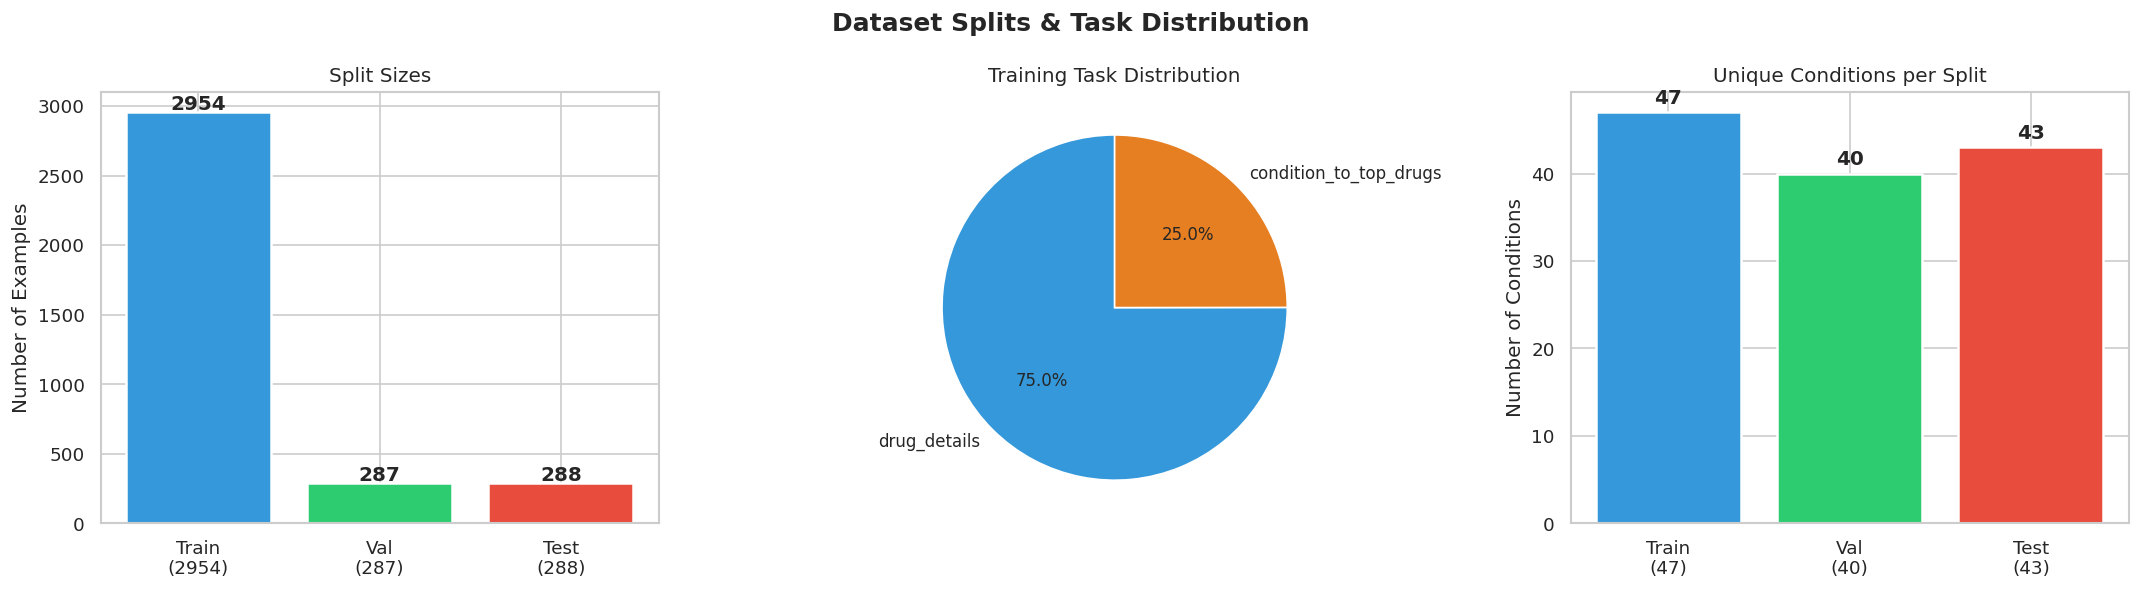

Saved: /content/curalm_plots/02_dataset_splits.png


In [ ]:
# Dataset split visualization
fig, charts = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Dataset Splits & Task Distribution", fontsize=15, fontweight="bold")


# Chart 1: Show the size of train, validation, and test sets

split_counts = [len(train_df), len(val_df), len(test_df)]
split_names = [
    f"Train\n({split_counts[0]})",
    f"Val\n({split_counts[1]})",
    f"Test\n({split_counts[2]})"
]

split_colors = ["#3498db", "#2ecc71", "#e74c3c"]

charts[0].bar(
    split_names,
    split_counts,
    color=split_colors,
    edgecolor="white",
    linewidth=1.5
)

charts[0].set_title("Split Sizes")
charts[0].set_ylabel("Number of Examples")

for index, value in enumerate(split_counts):
    charts[0].text(index, value + 20, str(value), ha="center", fontweight="bold")


# Chart 2: Show task distribution in the training set

task_counts = train_df["task"].value_counts()

charts[1].pie(
    task_counts.values,
    labels=task_counts.index,
    autopct="%1.1f%%",
    colors=["#3498db", "#e67e22"],
    startangle=90,
    textprops={"fontsize": 10},
)

charts[1].set_title("Training Task Distribution")


# الرسمة الثالثة وضحنا فيها  عدد الحالات الطبية المختلفة في كل قسم

condition_counts = [
    train_df["medical_condition"].nunique(),
    val_df["medical_condition"].nunique(),
    test_df["medical_condition"].nunique(),
]

condition_names = [
    f"Train\n({condition_counts[0]})",
    f"Val\n({condition_counts[1]})",
    f"Test\n({condition_counts[2]})"
]

charts[2].bar(
    condition_names,
    condition_counts,
    color=split_colors,
    edgecolor="white",
    linewidth=1.5
)

charts[2].set_title("Unique Conditions per Split")
charts[2].set_ylabel("Number of Conditions")

for index, value in enumerate(condition_counts):
    charts[2].text(index, value + 1, str(value), ha="center", fontweight="bold")



plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "02_dataset_splits.png"))
plt.show()

print(f"Saved: {PLOTS_DIR}/02_dataset_splits.png")

In [ ]:
# Save prepared training data

# Here we Select only the columns needed for training and evaluation
save_columns = [
    "task",
    "medical_condition",
    "drug_name",
    "generic_name",
    "prompt",
    "answer"
]


save_folder = BASE_DIR

# Save data as CSV files and Jsonl
train_df[save_columns].to_csv(os.path.join(save_folder, "train.csv"), index=False)
val_df[save_columns].to_csv(os.path.join(save_folder, "val.csv"), index=False)
test_df[save_columns].to_csv(os.path.join(save_folder, "test.csv"), index=False)

train_df[save_columns].to_json(
    os.path.join(save_folder, "train.jsonl"),
    orient="records",
    lines=True,
    force_ascii=False
)

val_df[save_columns].to_json(
    os.path.join(save_folder, "val.jsonl"),
    orient="records",
    lines=True,
    force_ascii=False
)

test_df[save_columns].to_json(
    os.path.join(save_folder, "test.jsonl"),
    orient="records",
    lines=True,
    force_ascii=False
)

print(f"Saved prepared data → {save_folder}")
print(f"train.csv / train.jsonl : {len(train_df):>5} rows")
print(f"val.csv   / val.jsonl   : {len(val_df):>5} rows")
print(f"test.csv  / test.jsonl  : {len(test_df):>5} rows")

Saved prepared data → /content/curalm_project
train.csv / train.jsonl :  2954 rows
val.csv   / val.jsonl   :   287 rows
test.csv  / test.jsonl  :   288 rows


## 8. Tokenization & Padding Token Setup


In [ ]:
# Padding Token Setup
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    print(f" Using eos_token as pad_token. Vocab size unchanged: {len(tokenizer)}")
tokenizer.padding_side = "left"



In [ ]:
# Tokenize full dataset
# هنا حولنا الأسئلة والإجابات لأرقام يقدر يفهمها المودل عشان يقدر يتدرب عليها.

from datasets import Dataset

max_length = 1536

# Find the token IDs for the answer marker [/INST]
answer_marker_ids = tokenizer.encode("[/INST]", add_special_tokens=False)
answer_marker_length = len(answer_marker_ids)

print(f"[/INST] marker tokens: {answer_marker_ids} (len={answer_marker_length})")


def find_answer_start(input_ids):
    # Find where the answer starts after [/INST]
    for index in range(len(input_ids) - answer_marker_length + 1):
        if input_ids[index:index + answer_marker_length] == answer_marker_ids:
            return index + answer_marker_length

    return -1


def tokenize_examples(examples):
    # Tokenize text and mask the prompt part.
    # The model should learn from the answer only.

    all_input_ids = []
    all_attention_masks = []
    all_labels = []

    for prompt, answer in zip(examples["prompt"], examples["answer"]):
        full_text = (
            f"<s>[INST] {prompt} [/INST] {answer.strip()}"
            f"{tokenizer.eos_token}"
        )

        encoded_text = tokenizer(
            full_text,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            add_special_tokens=False,
        )

        input_ids = encoded_text["input_ids"]
        attention_mask = encoded_text["attention_mask"]

        answer_start = find_answer_start(input_ids)

        if answer_start == -1:
            labels = [-100] * len(input_ids)
        else:
            labels = [
                -100 if (index < answer_start or attention_mask[index] == 0)
                else token_id
                for index, token_id in enumerate(input_ids)
            ]

        all_input_ids.append(input_ids)
        all_attention_masks.append(attention_mask)
        all_labels.append(labels)

    return {
        "input_ids": all_input_ids,
        "attention_mask": all_attention_masks,
        "labels": all_labels,
    }


# Columns used for tokenization
token_columns = ["task", "medical_condition", "drug_name", "generic_name", "prompt", "answer"]

# Convert pandas dataframes to Hugging Face datasets
train_hf = Dataset.from_pandas(train_df[token_columns])
val_hf = Dataset.from_pandas(val_df[token_columns])
test_hf = Dataset.from_pandas(test_df[token_columns])


# Apply tokenization
tokenized_train = train_hf.map(tokenize_examples, batched=True, desc="Tokenizing train")
tokenized_val = val_hf.map(tokenize_examples, batched=True, desc="Tokenizing val")
tokenized_test = test_hf.map(tokenize_examples, batched=True, desc="Tokenizing test")


# Keep only the columns needed by the model
model_columns = ["input_ids", "attention_mask", "labels"]

for dataset_name, dataset in [
    ("train", tokenized_train),
    ("val", tokenized_val),
    ("test", tokenized_test)
]:
    dataset = dataset.remove_columns([
        column for column in dataset.column_names
        if column not in model_columns
    ])

    dataset.set_format(type="torch", columns=model_columns)

    if dataset_name == "train":
        tokenized_train = dataset
    elif dataset_name == "val":
        tokenized_val = dataset
    else:
        tokenized_test = dataset


# Quick check to make sure masking works correctly
sample = tokenized_train[0]

input_ids = sample["input_ids"].tolist()
labels = sample["labels"].tolist()

first_answer_token = next(
    (index for index, label in enumerate(labels) if label != -100),
    None
)

if first_answer_token is not None:
    decoded_token = tokenizer.decode([input_ids[first_answer_token]])

    print(f"First answer token index: {first_answer_token}")
    print(f"First answer token: {repr(decoded_token)}")
    print(f"Masked prompt tokens: {labels.count(-100)} / {len(labels)}")


print(
    f"\nTokenized datasets — "
    f"Train: {len(tokenized_train)}, "
    f"Val: {len(tokenized_val)}, "
    f"Test: {len(tokenized_test)}"
)


# Check that EOS token is added correctly
test_tokenization = tokenizer(
    f"<s>[INST] test [/INST] answer{tokenizer.eos_token}",
    add_special_tokens=False,
)

assert tokenizer.eos_token_id in test_tokenization["input_ids"], (
    f"EOS token ID {tokenizer.eos_token_id} not found. "
    f"Check tokenizer.eos_token = '{tokenizer.eos_token}'"
)

print(
    f"EOS token check passed — "
    f"ID={tokenizer.eos_token_id}, "
    f"token='{tokenizer.eos_token}', "
    f"position={test_tokenization['input_ids'].index(tokenizer.eos_token_id)}"
)

[/INST] marker tokens: [733, 28748, 16289, 28793] (len=4)


Tokenizing train:   0%|          | 0/2954 [00:00<?, ? examples/s]

Tokenizing val:   0%|          | 0/287 [00:00<?, ? examples/s]

Tokenizing test:   0%|          | 0/288 [00:00<?, ? examples/s]

First answer token index: 1382
First answer token: 'Drug'
Masked prompt tokens: 1382 / 1536

Tokenized datasets — Train: 2954, Val: 287, Test: 288
EOS token check passed — ID=2, token='</s>', position=10


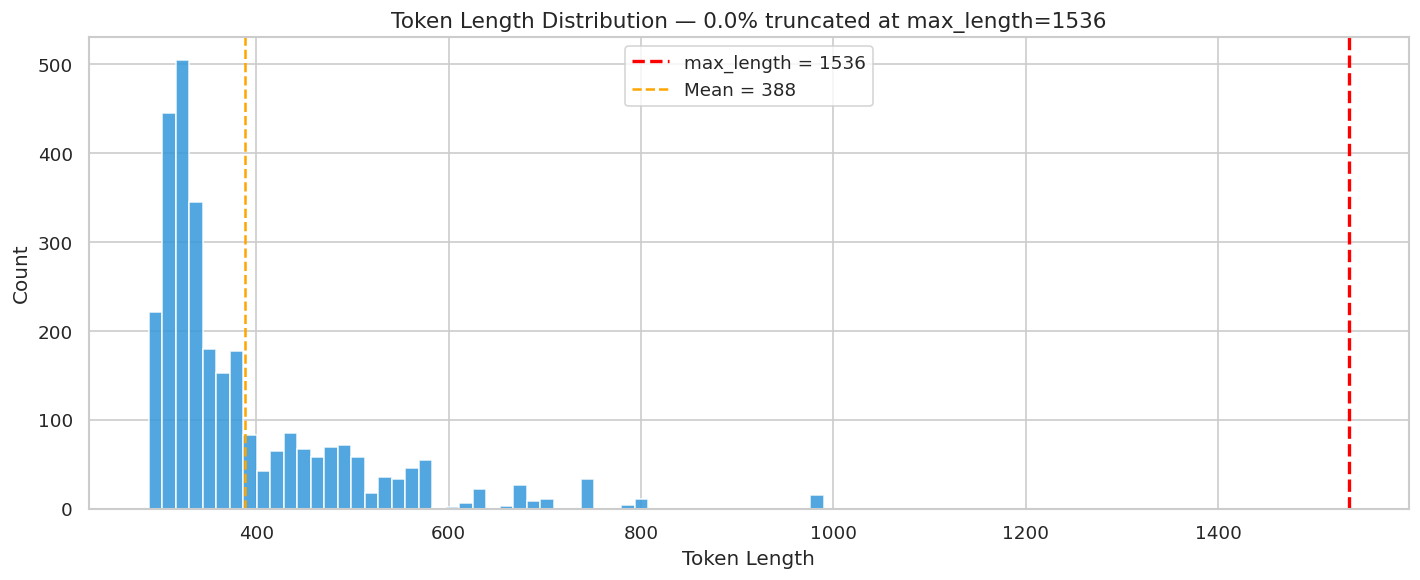

Saved: /content/curalm_plots/03_token_length_dist.png
Min      : 288
Mean     : 388
Max      : 990
Median   : 343
Truncated: 0.0% (0 / 2954 examples)

Good. No truncation. max_length=1536 covers all examples.


In [ ]:
# Token length distribution plot
# This plot shows if the training texts are too long or fit within max_length.

def build_full_text(row):
    return f"<s>[INST] {row['prompt']} [/INST] {row['answer'].strip()}</s>"


# Count the number of tokens for each training example
token_lengths = train_df.apply(
    lambda row: len(tokenizer(build_full_text(row), truncation=False)["input_ids"]),
    axis=1,
)


fig, chart = plt.subplots(figsize=(12, 5))

chart.hist(
    token_lengths,
    bins=50,
    color="#3498db",
    edgecolor="white",
    alpha=0.85
)

# Red line shows the maximum allowed token length
chart.axvline(
    max_length,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"max_length = {max_length}"
)

# Orange line shows the average token length
chart.axvline(
    token_lengths.mean(),
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {token_lengths.mean():.0f}"
)


truncated_percent = (token_lengths > max_length).mean() * 100

chart.set_title(
    f"Token Length Distribution — {truncated_percent:.1f}% truncated at max_length={max_length}",
    fontsize=13
)

chart.set_xlabel("Token Length")
chart.set_ylabel("Count")
chart.legend(fontsize=11)


plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "03_token_length_dist.png"))
plt.show()


print(f"Saved: {PLOTS_DIR}/03_token_length_dist.png")
print(f"Min      : {token_lengths.min()}")
print(f"Mean     : {token_lengths.mean():.0f}")
print(f"Max      : {token_lengths.max()}")
print(f"Median   : {token_lengths.median():.0f}")
print(
    f"Truncated: {truncated_percent:.1f}% "
    f"({(token_lengths > max_length).sum()} / {len(token_lengths)} examples)"
)


# Show warning if many examples are too long
if truncated_percent > 10:
    print(f"\nWarning: {truncated_percent:.1f}% truncation is high. Consider increasing max_length.")
elif truncated_percent == 0:
    print(f"\nGood. No truncation. max_length={max_length} covers all examples.")

## 9. Full Training


In [ ]:
# Full training configuration
# This step prepares the final training settings for the full dataset.

import os
import math
import shutil
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback


# Main training settings
train_batch_size = 4
accumulation_steps = 8
epochs = 4

learning_rate = 5e-5
eval_steps = 64
early_stopping_patience = 4


# Calculate training steps
steps_per_epoch = math.ceil(
    len(tokenized_train) / (train_batch_size * accumulation_steps)
)

total_steps = steps_per_epoch * epochs


# Gradual learning rate start
# The learning rate starts small and then increases slowly at the beginning of training.
learning_rate_start_steps = max(20, int(total_steps * 0.05))


print("Phase 2 — Full Training Configuration:")
print(f"Steps per epoch       : {steps_per_epoch}")
print(f"Total steps           : {total_steps}")
print(f"Learning rate start   : {learning_rate_start_steps} steps")
print(f"Eval every            : {eval_steps} steps")
print(f"Epochs                : {epochs}")
print(f"Learning rate         : {learning_rate}")
print(f"Weight decay          : 0.1")
print(f"Early stopping        : patience={early_stopping_patience}")


# Remove old checkpoints before full training
for item in os.listdir(OUTPUT_DIR):
    item_path = os.path.join(OUTPUT_DIR, item)

    if item.startswith("checkpoint-") and os.path.isdir(item_path):
        shutil.rmtree(item_path)
        print(f"Removed old checkpoint: {item}")


# Full training arguments
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=accumulation_steps,
    num_train_epochs=epochs,
    learning_rate=learning_rate,
    logging_steps=10,
    logging_first_step=True,
    eval_steps=eval_steps,
    save_steps=eval_steps,
    eval_strategy="steps",
    save_strategy="steps",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    fp16=not use_bf16,
    bf16=use_bf16,
    optim="paged_adamw_8bit",
    lr_scheduler_type="cosine",
    warmup_steps=learning_rate_start_steps,
    weight_decay=0.1,
    max_grad_norm=0.3,
    save_total_limit=2,
    report_to="none",
    remove_unused_columns=False,
    dataloader_pin_memory=True,
    label_smoothing_factor=0,
    seed=42,
    data_seed=42,
)


print("\nFull training arguments are ready.")
print(f"Use EarlyStoppingCallback(early_stopping_patience={early_stopping_patience}) in the Trainer.")


Phase 2 — Full Training Configuration:
Steps per epoch       : 93
Total steps           : 372
Learning rate start   : 20 steps
Eval every            : 64 steps
Epochs                : 4
Learning rate         : 5e-05
Weight decay          : 0.1
Early stopping        : patience=4

Full training arguments are ready.
Use EarlyStoppingCallback(early_stopping_patience=4) in the Trainer.


In [22]:
# Create trainer and start full training
# This step starts the real training using the full training dataset.

from transformers import default_data_collator

model.config.use_cache = False
model.train()
model.gradient_checkpointing_enable()


# Check trainable parameters and one sample answer
trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

sample_answer_tokens = [
    token for token in tokenized_train[0]["labels"]
    if (token if isinstance(token, int) else token.item()) != -100
]


print(f"Trainable parameters : {trainable_params:,}")
print(f"Training data size   : {len(tokenized_train)}")
print(f"Sample answer tokens : {len(sample_answer_tokens)}")
print(f"Model training mode  : {model.training}")


# Create Trainer for full training
full_trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=default_data_collator,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=6)
    ],
)


print("\nStarting full training...")
full_train_result = full_trainer.train()

print("Full training is complete.")


# Switch model back to evaluation mode after training
model.eval()
model.config.use_cache = True

print("Model is ready for evaluation.")

Trainable parameters : 83,886,080
Training data size   : 2954
Sample answer tokens : 154
Model training mode  : True

Starting full training...


Step,Training Loss,Validation Loss
64,0.316973,0.543759
128,0.170126,0.453623
192,0.100133,0.402318
256,0.059207,0.377085
320,0.025236,0.401584
372,0.021996,0.399349


Full training is complete.
Model is ready for evaluation.


In [23]:
# Extract training history
# This part collects loss values and learning rate from the full training logs.

import math
import numpy as np

# Use the full training trainer
training_logs = full_trainer.state.log_history

train_losses = []
eval_losses = []
learning_rates = []


if not training_logs:
    print("WARNING: Training history is empty. Training may have been interrupted.")

else:
    # Get training loss values
    train_losses = [
        (log["step"], log["loss"])
        for log in training_logs
        if "loss" in log and "eval_loss" not in log
    ]

    # Get evaluation loss values
    eval_losses = [
        (log["step"], log["eval_loss"])
        for log in training_logs
        if "eval_loss" in log
    ]

    # Get learning rate values
    learning_rates = [
        (log["step"], log["learning_rate"])
        for log in training_logs
        if "learning_rate" in log
    ]

    print(f"Captured {len(train_losses)} train loss points.")
    print(f"Captured {len(eval_losses)} eval loss points.")

    if full_trainer.state.best_metric is not None:
        print(f"Best eval loss: {full_trainer.state.best_metric:.4f}")
    else:
        print("Best eval loss: N/A")

    print(f"Best checkpoint: {full_trainer.state.best_model_checkpoint}")

Captured 38 train loss points.
Captured 6 eval loss points.
Best eval loss: 0.3771
Best checkpoint: /content/curalm_output/checkpoint-256


## 10. Training Curves & Analysis Plots


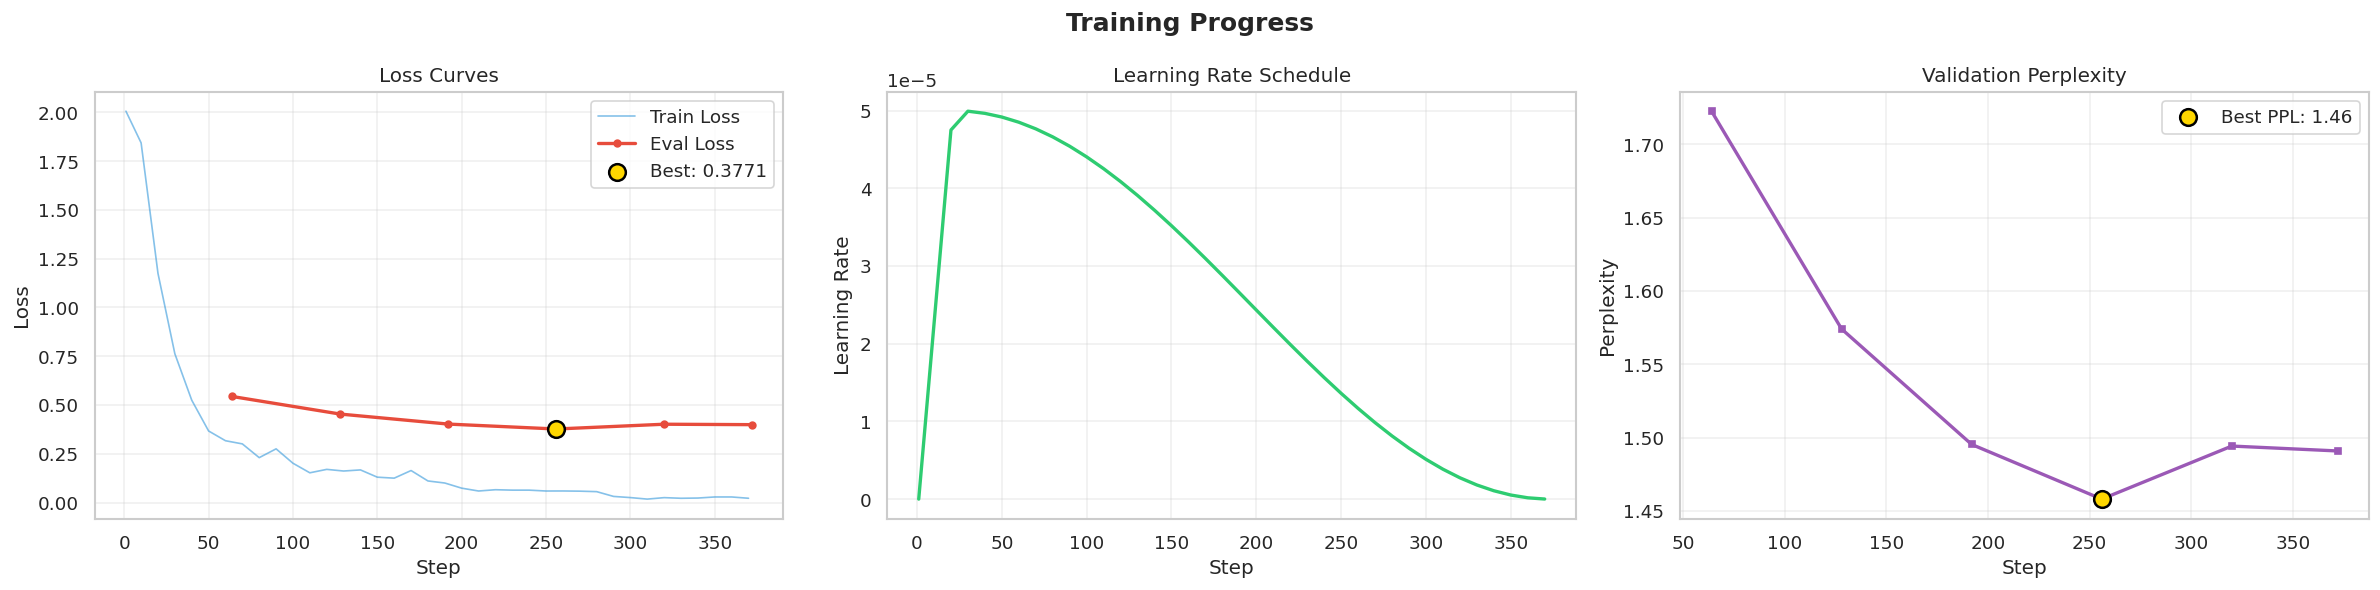

Saved: /content/curalm_plots/04_training_curves.png


In [25]:
# Plot training progress
# This figure shows loss, learning rate, and validation perplexity during training.

import os
import math
import numpy as np
import matplotlib.pyplot as plt

fig, charts = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle("Training Progress", fontsize=15, fontweight="bold")


# Chart 1: Training loss and validation loss
# Lower loss usually means the model is learning better.

if train_losses:
    train_steps, train_loss_values = zip(*train_losses)

    charts[0].plot(
        train_steps,
        train_loss_values,
        color="#3498db",
        alpha=0.6,
        linewidth=1,
        label="Train Loss"
    )

if eval_losses:
    eval_loss_steps, eval_loss_values = zip(*eval_losses)

    charts[0].plot(
        eval_loss_steps,
        eval_loss_values,
        color="#e74c3c",
        linewidth=2,
        marker="o",
        markersize=4,
        label="Eval Loss"
    )

    # Mark the best validation loss point
    best_eval_index = int(np.argmin(eval_loss_values))

    charts[0].scatter(
        [eval_loss_steps[best_eval_index]],
        [eval_loss_values[best_eval_index]],
        color="gold",
        s=100,
        zorder=5,
        edgecolors="black",
        linewidths=1.5,
        label=f"Best: {eval_loss_values[best_eval_index]:.4f}",
    )

if not train_losses and not eval_losses:
    charts[0].text(
        0.5,
        0.5,
        "No loss data",
        ha="center",
        va="center",
        transform=charts[0].transAxes,
        color="gray",
        fontsize=12
    )

charts[0].set_title("Loss Curves")
charts[0].set_xlabel("Step")
charts[0].set_ylabel("Loss")
charts[0].legend()
charts[0].grid(True, alpha=0.3)


# Chart 2: Learning rate schedule
# This shows how the learning rate changed during training.

if learning_rates:
    learning_rate_steps, learning_rate_values = zip(*learning_rates)

    charts[1].plot(
        learning_rate_steps,
        learning_rate_values,
        color="#2ecc71",
        linewidth=2
    )

    charts[1].ticklabel_format(
        style="scientific",
        axis="y",
        scilimits=(0, 0)
    )

else:
    charts[1].text(
        0.5,
        0.5,
        "No learning rate data",
        ha="center",
        va="center",
        transform=charts[1].transAxes,
        color="gray",
        fontsize=11
    )

charts[1].set_title("Learning Rate Schedule")
charts[1].set_xlabel("Step")
charts[1].set_ylabel("Learning Rate")
charts[1].grid(True, alpha=0.3)


# Chart 3: Validation perplexity
# Perplexity is another way to measure model performance. Lower is better.

if eval_losses:
    validation_perplexity = [
        math.exp(min(loss, 20))
        for loss in eval_loss_values
    ]

    charts[2].plot(
        eval_loss_steps,
        validation_perplexity,
        color="#9b59b6",
        linewidth=2,
        marker="s",
        markersize=4
    )

    # Mark the best perplexity point
    best_perplexity_index = int(np.argmin(validation_perplexity))

    charts[2].scatter(
        [eval_loss_steps[best_perplexity_index]],
        [validation_perplexity[best_perplexity_index]],
        color="gold",
        s=100,
        zorder=5,
        edgecolors="black",
        linewidths=1.5,
        label=f"Best PPL: {validation_perplexity[best_perplexity_index]:.2f}",
    )

    charts[2].legend()

else:
    charts[2].text(
        0.5,
        0.5,
        "No eval data",
        ha="center",
        va="center",
        transform=charts[2].transAxes,
        color="gray",
        fontsize=12
    )

charts[2].set_title("Validation Perplexity")
charts[2].set_xlabel("Step")
charts[2].set_ylabel("Perplexity")
charts[2].grid(True, alpha=0.3)


# Save and show the final figure
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "04_training_curves.png"), dpi=150)
plt.show()

print(f"Saved: {PLOTS_DIR}/04_training_curves.png")

In [26]:
# Install required libraries
# This cell installs the main packages needed for model training and evaluation.

import subprocess
import sys

packages = [
    "bitsandbytes>=0.46.1",
    "transformers",
    "accelerate",
    "peft",
    "trl",
    "sentencepiece",
    "safetensors",
    "datasets",
    "sentence-transformers",
    "faiss-cpu",
    "bert-score",
    "scikit-learn",
]

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "-q",
    "install",
    "-U",
    *packages
])

print("All required libraries installed successfully.")

All required libraries installed successfully.


In [27]:
# Save final trained adapter
# This saves the final LoRA adapter after full training.

import os

final_adapter_path = os.path.join(OUTPUT_DIR, "qlora_full_adapter")
os.makedirs(final_adapter_path, exist_ok=True)

# Save from the trainer model to make sure we save the trained adapter
full_trainer.model.save_pretrained(final_adapter_path)
tokenizer.save_pretrained(final_adapter_path)

print("Final adapter saved at:", final_adapter_path)
print("Saved files:", os.listdir(final_adapter_path))

# Check important adapter file
if os.path.exists(os.path.join(final_adapter_path, "adapter_config.json")):
    print("Adapter saved correctly.")
else:
    print("ERROR: adapter_config.json was not saved.")

Final adapter saved at: /content/curalm_output/qlora_full_adapter
Saved files: ['chat_template.jinja', 'README.md', 'adapter_model.safetensors', 'adapter_config.json', 'tokenizer_config.json', 'tokenizer.json']
Adapter saved correctly.


In [28]:
# Reload model from final trained adapter

import os
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

model_name = "BioMistral/BioMistral-7B-DARE"

# Use the same path used in the saving cell
adapter_path = os.path.join(OUTPUT_DIR, "qlora_full_adapter")

print("Checking adapter path:", adapter_path)

if not os.path.exists(os.path.join(adapter_path, "adapter_config.json")):
    print("Files found:", os.listdir(adapter_path) if os.path.isdir(adapter_path) else "Folder not found")
    raise FileNotFoundError("Adapter file not found. Check the saving cell.")

# Choose loading dtype based on GPU
gpu_major, _ = torch.cuda.get_device_capability(0)
load_dtype = torch.bfloat16 if gpu_major >= 8 else torch.float16

# 4-bit loading configuration
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=load_dtype,
)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

# Load base model
base_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quant_config,
    device_map="auto",
)

# Attach final trained adapter
model = PeftModel.from_pretrained(base_model, adapter_path)
model.eval()

print("Model ready. Final adapter loaded successfully.")
print("Adapter loaded from:", adapter_path)

Checking adapter path: /content/curalm_output/qlora_full_adapter


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Model ready. Final adapter loaded successfully.
Adapter loaded from: /content/curalm_output/qlora_full_adapter


In [29]:
# Evaluate on validation and test sets
# This step checks the final model performance after training.

import math
from transformers import Trainer, default_data_collator

model.eval()


# Use the full trainer if it already exists
if "full_trainer" in globals():
    eval_trainer = full_trainer
else:
    eval_trainer = Trainer(
        model=model,
        args=training_args,
        eval_dataset=tokenized_val,
        data_collator=default_data_collator,
    )


# Remove notebook progress callback if it causes display issues
try:
    from transformers.utils.notebook import NotebookProgressCallback
    eval_trainer.remove_callback(NotebookProgressCallback)
except (ImportError, ValueError):
    pass


# Make sure validation and test data are ready
if len(tokenized_val) == 0:
    raise RuntimeError("Validation dataset is empty. Re-run the tokenization cell.")

if len(tokenized_test) == 0:
    raise RuntimeError("Test dataset is empty. Re-run the tokenization cell.")


# Evaluate validation and test data
val_metrics = eval_trainer.evaluate(eval_dataset=tokenized_val)
test_metrics = eval_trainer.evaluate(
    eval_dataset=tokenized_test,
    metric_key_prefix="test"
)


# Calculate perplexity from loss
if "eval_loss" in val_metrics:
    val_metrics["eval_perplexity"] = math.exp(min(val_metrics["eval_loss"], 20))

if "test_loss" in test_metrics:
    test_metrics["test_perplexity"] = math.exp(min(test_metrics["test_loss"], 20))


# Format numbers for clean printing
def format_metric(value):
    try:
        return f"{float(value):.4f}"
    except (TypeError, ValueError):
        return str(value)


# Print validation results
print("Validation Metrics:")
for name, value in val_metrics.items():
    print(f"{name}: {format_metric(value)}")


# Print test results
print("\nTest Metrics:")
for name, value in test_metrics.items():
    print(f"{name}: {format_metric(value)}")

[transformers] early stopping required metric_for_best_model, but did not find eval_loss so early stopping is disabled


Validation Metrics:
eval_loss: 0.3771
eval_runtime: 32.7979
eval_samples_per_second: 8.7510
eval_steps_per_second: 8.7510
epoch: 4.0000
eval_perplexity: 1.4580

Test Metrics:
test_loss: 0.3897
test_runtime: 32.9884
test_samples_per_second: 8.7300
test_steps_per_second: 8.7300
epoch: 4.0000
test_perplexity: 1.4766


## 11. Comprehensive Model Evaluation


In [30]:
# Evaluate on validation and test sets
# This step checks the final model performance after training.

import math

model.eval()


# Use the correct trainer name
eval_trainer = full_trainer if "full_trainer" in globals() else trainer


# Remove notebook progress callback if it causes display issues
try:
    from transformers.utils.notebook import NotebookProgressCallback
    eval_trainer.remove_callback(NotebookProgressCallback)
except (ImportError, ValueError):
    pass


# Make sure validation and test datasets are ready
if len(tokenized_val) == 0:
    raise RuntimeError("Validation dataset is empty. Re-run the tokenization cell.")

if len(tokenized_test) == 0:
    raise RuntimeError("Test dataset is empty. Re-run the tokenization cell.")


# Evaluate validation and test datasets
val_metrics = eval_trainer.evaluate(eval_dataset=tokenized_val)

test_metrics = eval_trainer.evaluate(
    eval_dataset=tokenized_test,
    metric_key_prefix="test"
)


# Convert loss to perplexity
if "eval_loss" in val_metrics:
    val_metrics["eval_perplexity"] = math.exp(min(val_metrics["eval_loss"], 20))

if "test_loss" in test_metrics:
    test_metrics["test_perplexity"] = math.exp(min(test_metrics["test_loss"], 20))


# Format metric numbers
def format_metric(value):
    try:
        return f"{float(value):.4f}"
    except (TypeError, ValueError):
        return str(value)


print("Validation Metrics:")
for name, value in val_metrics.items():
    print(f"{name}: {format_metric(value)}")


print("\nTest Metrics:")
for name, value in test_metrics.items():
    print(f"{name}: {format_metric(value)}")

[transformers] early stopping required metric_for_best_model, but did not find eval_loss so early stopping is disabled


Validation Metrics:
eval_loss: 0.3771
eval_runtime: 32.8077
eval_samples_per_second: 8.7480
eval_steps_per_second: 8.7480
epoch: 4.0000
eval_perplexity: 1.4580

Test Metrics:
test_loss: 0.3897
test_runtime: 32.9851
test_samples_per_second: 8.7310
test_steps_per_second: 8.7310
epoch: 4.0000
test_perplexity: 1.4766


In [31]:
# Define inference functions
# These functions are used to test the trained model after training.

import faiss
import pickle
import torch
from sentence_transformers import SentenceTransformer


# Load embedding model if it was not loaded before
if "embedder" not in globals():
    embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")


# Use the correct RAG file paths
rag_index_file = RAG_INDEX_PATH if "RAG_INDEX_PATH" in globals() else rag_index_path
rag_docs_file = RAG_DOCS_PATH if "RAG_DOCS_PATH" in globals() else rag_docs_path


# Load RAG index and documents if they are not loaded
if "rag_index" not in globals():
    rag_index = faiss.read_index(rag_index_file)

    with open(rag_docs_file, "rb") as file:
        rag_docs = pickle.load(file)

    print(f"RAG index loaded: {rag_index.ntotal} docs")


# Use the same max length from tokenization
generation_max_length = max_length if "max_length" in globals() else MAX_LENGTH


def search_rag(query, top_k=3):
    # Search for the most relevant drug documents from our dataset.
    # بالعربي: هنا نبحث في قاعدة المعرفة ونجيب أقرب معلومات للسؤال.

    query_vector = embedder.encode(
        [query],
        normalize_embeddings=True
    ).astype("float32")

    scores, indexes = rag_index.search(query_vector, top_k)

    results = [
        rag_docs[index]
        for index in indexes[0]
        if index >= 0
    ]

    return results


def make_rag_context(docs):
    # Convert retrieved documents into a clear text block for the model.
    # بالعربي: هنا نحول نتائج البحث إلى نص مرتب نعطيه للمودل قبل الإجابة.

    context_lines = []

    for number, doc in enumerate(docs, start=1):
        context_lines.append(
            f"[Reference {number}] "
            f"Drug: {doc['drug']} | "
            f"Generic: {doc['generic']} | "
            f"Side effects: {doc['side_effects'][:250]}"
        )

    return "\n".join(context_lines)


def generate_drug_details(condition, drug_name, max_new_tokens=350, use_rag=True):
    # Generate generic name and possible side effects for a given drug.
    # بالعربي: هذه الدالة تعطي الاسم العلمي والأعراض الجانبية بناءً على المرض واسم الدواء.

    rag_text = ""

    if use_rag:
        search_query = f"{condition} {drug_name}"
        related_docs = search_rag(search_query, top_k=3)

        rag_text = (
            "\n\nRelevant references:\n"
            + make_rag_context(related_docs)
            + "\n"
        )

    prompt = (
        "Task: Given a medical condition and a drug name, provide the generic name "
        "and possible side effects (comma-separated, up to 5 items) "
        "using the standard abbreviations below.\n"
        f"{_ABBREV_LEGEND}\n"
        f"{rag_text}"
        f"\nMedical condition: {condition}"
        f"\nDrug name: {drug_name}\n"
    )

    model_prompt = f"<s>[INST] {prompt} [/INST]"

    inputs = tokenizer(
        model_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=generation_max_length,
        add_special_tokens=False,
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.eos_token_id,
            repetition_penalty=1.1,
        )

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True,
    ).strip()

    return answer


def generate_from_condition(condition, top_k=3, max_new_tokens=500, use_rag=True):
    # Generate top drug recommendations for a medical condition.
    # بالعربي: هذه الدالة تعطي أفضل أدوية متوقعة للحالة الطبية مع الاسم العلمي والأعراض.

    rag_text = ""

    if use_rag:
        related_docs = search_rag(condition, top_k=5)

        rag_text = (
            "\n\nRelevant references:\n"
            + make_rag_context(related_docs)
            + "\n"
        )

    prompt = (
        f"Task: Given a medical condition, predict the top {top_k} likely drugs "
        "and provide the generic name and possible side effects (comma-separated, "
        "up to 5 items) for each drug using the standard abbreviations below.\n"
        f"{_ABBREV_LEGEND}\n"
        f"{rag_text}"
        f"\nMedical condition: {condition}\n"
    )

    model_prompt = f"<s>[INST] {prompt} [/INST]"

    inputs = tokenizer(
        model_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=generation_max_length,
        add_special_tokens=False,
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.eos_token_id,
            repetition_penalty=1.1,
        )

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True,
    ).strip()

    return answer


# Keep old function name in case another cell uses it
retrieve = search_rag

print("Inference functions are ready.")

Inference functions are ready.


In [32]:
# Define evaluation metrics
# These functions compare model outputs with the correct answers.

from collections import Counter

!pip install bert-score -q

from bert_score import score as bert_score_function
import numpy as np
import re


# Create a reverse map to convert abbreviations back to full side-effect names
abbrev_reverse_map = {}

for full_name, short_name in SIDE_EFFECT_ABBREV.items():
    if short_name not in abbrev_reverse_map or len(full_name) < len(abbrev_reverse_map[short_name]):
        abbrev_reverse_map[short_name] = full_name


# Regex pattern to find abbreviation tokens
abbrev_pattern = re.compile(
    r'\b(' + '|'.join(
        re.escape(short_name)
        for short_name in sorted(abbrev_reverse_map, key=len, reverse=True)
    ) + r')\b'
)


def expand_abbreviations(text):
    # Convert short side-effect tokens back to full words before evaluation.
    if not text:
        return text

    return abbrev_pattern.sub(
        lambda match: abbrev_reverse_map[match.group(1)],
        text
    )


def compute_bertscore_batch(predictions, references, lang="en", batch_size=16):
    # Compute BERTScore for a group of predictions and correct answers.

    clean_predictions = [
        expand_abbreviations(pred) if pred and pred.strip() else " "
        for pred in predictions
    ]

    clean_references = [
        expand_abbreviations(ref) if ref and ref.strip() else " "
        for ref in references
    ]

    precision, recall, f1 = bert_score_function(
        clean_predictions,
        clean_references,
        lang=lang,
        batch_size=batch_size,
        verbose=False
    )

    return precision.numpy(), recall.numpy(), f1.numpy()


def parse_drug_details_output(text):
    # Extract generic name and side effects from the model output.

    first_header = re.search(
        r"(Generic\s*name|Possible\s*side\s*effects?)",
        text,
        re.IGNORECASE
    )

    if first_header:
        text = text[first_header.start():]

    generic_name = ""
    side_effects = ""

    generic_match = re.search(
        r"generic\s*name\s*[:\-]?\s*(.+?)$",
        text,
        re.IGNORECASE | re.MULTILINE
    )

    if generic_match:
        generic_name = generic_match.group(1).strip()

    side_match = re.search(
        r"(?:possible\s+)?side\s*effects?\s*[:\-]?\s*(.+)",
        text,
        re.IGNORECASE | re.DOTALL
    )

    if side_match:
        raw_side_effects = side_match.group(1).strip()

        side_items = [
            item.strip().rstrip(".,;")
            for item in re.split(r"[,\n;]+", raw_side_effects)
            if item.strip() and len(item.strip()) > 1
        ]

        side_effects = ", ".join(side_items[:5])

    return generic_name, side_effects


def parse_top_drugs_output(text):
    # Extract the top drug names from the model output.

    drug_names = []

    for match in re.finditer(
        r'Drug\s*\d*\s*[:\-]\s*([A-Za-z][^\n,;/]{2,50}?)(?:\s*[\n,;]|Generic|Side|$)',
        text,
        re.IGNORECASE
    ):
        drug_name = match.group(1).strip().rstrip('.,')

        if drug_name:
            drug_names.append(drug_name)

    if not drug_names:
        for match in re.finditer(
            r'^\s*\d+[\.\)]\s*([A-Za-z][^\n,;/]{2,40}?)(?:\s*[-–]|\s*Generic|\s*$)',
            text,
            re.IGNORECASE | re.MULTILINE
        ):
            drug_name = match.group(1).strip().rstrip('.,')

            if drug_name:
                drug_names.append(drug_name)

    if not drug_names:
        first_line = text.strip().split('\n')[0]

        if ',' in first_line and len(first_line) < 200:
            drug_names = [
                drug.strip().rstrip('.,')
                for drug in first_line.split(',')
                if drug.strip()
            ]

    return drug_names[:3]


def tokenize_text(text):
    # Split text into simple lowercase tokens.
    return text.lower().split()


def token_f1(prediction, reference):
    # Calculate token-level precision, recall, and F1 score.

    prediction_tokens = tokenize_text(prediction)
    reference_tokens = tokenize_text(reference)

    if not reference_tokens and not prediction_tokens:
        return 1.0, 1.0, 1.0

    if not reference_tokens or not prediction_tokens:
        return 0.0, 0.0, 0.0

    common_tokens = Counter(prediction_tokens) & Counter(reference_tokens)
    common_count = sum(common_tokens.values())

    if common_count == 0:
        return 0.0, 0.0, 0.0

    precision = common_count / len(prediction_tokens)
    recall = common_count / len(reference_tokens)
    f1 = 2 * precision * recall / (precision + recall)

    return precision, recall, f1


def token_f1_abbrev(prediction, reference):
    # Calculate token F1 after expanding side-effect abbreviations.

    return token_f1(
        expand_abbreviations(prediction),
        expand_abbreviations(reference)
    )


def normalized_exact_match(prediction, reference):
    # Check if prediction and reference match after simple text cleaning.

    def normalize_text(text):
        text = expand_abbreviations(text)
        text = text.strip().lower()
        text = re.sub(r'\s*\([^)]*?route\)', '', text)
        text = re.sub(r'\s*\([^)]*?\)', '', text)
        text = re.sub(r'\band\b', ',', text)
        text = re.sub(r'[^\w\s,]', '', text)
        text = re.sub(r'\s+', ' ', text).strip()

        return text

    clean_prediction = normalize_text(prediction)
    clean_reference = normalize_text(reference)

    if clean_prediction == clean_reference:
        return 1

    prediction_tokens = set(clean_prediction.split())
    reference_tokens = set(clean_reference.split())

    if reference_tokens and len(prediction_tokens & reference_tokens) / len(reference_tokens) >= 0.85:
        return 1

    return 0


print("Evaluation metrics defined.")

Evaluation metrics defined.


## 12. Full Inference-Based Evaluation on Test Set


In [33]:
# Run inference evaluation with RAG comparison
# This part tests the model with RAG and without RAG, then compares the results.

from tqdm.auto import tqdm

model.eval()


def run_drug_detail_eval(use_rag):
    # Evaluate the task: condition + drug name -> generic name + side effects.

    mode_name = "RAG" if use_rag else "No RAG"
    drug_detail_rows = test_df[test_df["task"] == "drug_details"].copy()

    results = []

    bert_predicted_sides = []
    bert_correct_sides = []
    bert_predicted_answers = []
    bert_correct_answers = []

    for _, row in tqdm(
        drug_detail_rows.iterrows(),
        total=len(drug_detail_rows),
        desc=f"Drug details [{mode_name}]"
    ):
        condition = row["medical_condition"]
        drug_name = row["drug_name"]
        correct_answer = row["answer"]

        correct_generic, correct_side = parse_drug_details_output(correct_answer)

        predicted_answer = generate_drug_details(
            condition,
            drug_name,
            use_rag=use_rag
        )

        predicted_generic, predicted_side = parse_drug_details_output(predicted_answer)

        generic_match = normalized_exact_match(predicted_generic, correct_generic)

        side_precision, side_recall, side_f1 = token_f1_abbrev(
            predicted_side,
            correct_side
        )

        _, _, answer_f1 = token_f1_abbrev(
            predicted_answer,
            correct_answer
        )

        bert_predicted_sides.append(predicted_side or " ")
        bert_correct_sides.append(correct_side or " ")
        bert_predicted_answers.append(predicted_answer or " ")
        bert_correct_answers.append(correct_answer or " ")

        results.append({
            "condition": condition,
            "drug": drug_name,
            "gold_generic": correct_generic,
            "pred_generic": predicted_generic,
            "generic_em": generic_match,
            "gold_side": correct_side,
            "pred_side": predicted_side,
            "side_precision": side_precision,
            "side_recall": side_recall,
            "side_f1": side_f1,
            "answer_f1": answer_f1,
            "pred_raw": predicted_answer,
            "rag": use_rag,
            "bert_side_f1": 0.0,
            "bert_ans_f1": 0.0,
        })

    # BERTScore is calculated after all predictions to make it faster.
    print(f"\nComputing BERTScore [{mode_name}] - side effects...")
    _, _, side_bert_scores = compute_bertscore_batch(
        bert_predicted_sides,
        bert_correct_sides
    )

    print(f"Computing BERTScore [{mode_name}] - full answers...")
    _, _, answer_bert_scores = compute_bertscore_batch(
        bert_predicted_answers,
        bert_correct_answers
    )

    for index, result in enumerate(results):
        result["bert_side_f1"] = float(side_bert_scores[index])
        result["bert_ans_f1"] = float(answer_bert_scores[index])

    return pd.DataFrame(results)


def run_condition_eval(use_rag):
    # Evaluate the task: condition -> top 3 drugs.

    mode_name = "RAG" if use_rag else "No RAG"
    condition_rows = test_df[test_df["task"] == "condition_to_top_drugs"].copy()

    results = []

    for _, row in tqdm(
        condition_rows.iterrows(),
        total=len(condition_rows),
        desc=f"Condition to drugs [{mode_name}]"
    ):
        condition = row["medical_condition"]
        correct_answer = row["answer"]

        correct_drugs = parse_top_drugs_output(correct_answer)

        predicted_answer = generate_from_condition(
            condition,
            top_k=3,
            use_rag=use_rag
        )

        predicted_drugs = parse_top_drugs_output(predicted_answer)

        predicted_drugs_lower = [
            drug.lower()
            for drug in predicted_drugs
        ]

        hits = []

        for correct_drug in correct_drugs:
            correct_drug_lower = correct_drug.lower()

            hit = int(
                correct_drug_lower in predicted_drugs_lower
                or any(
                    correct_drug_lower in predicted_drug
                    or predicted_drug in correct_drug_lower
                    for predicted_drug in predicted_drugs_lower
                )
            )

            hits.append(hit)

        drug_hit = max(hits) if hits else 0

        _, _, answer_f1 = token_f1_abbrev(
            predicted_answer,
            correct_answer
        )

        results.append({
            "condition": condition,
            "gold_drugs": correct_drugs,
            "pred_drugs": predicted_drugs,
            "drug_hit": drug_hit,
            "answer_f1": answer_f1,
            "pred_raw": predicted_answer,
            "rag": use_rag,
        })

    return pd.DataFrame(results)


# Run all evaluation cases
print("=" * 60)
print("Running drug details WITH RAG")
print("=" * 60)
detail_results_df_rag = run_drug_detail_eval(use_rag=True)

print("\n" + "=" * 60)
print("Running drug details WITHOUT RAG")
print("=" * 60)
detail_results_df_norag = run_drug_detail_eval(use_rag=False)

print("\n" + "=" * 60)
print("Running condition-to-drugs WITHOUT RAG")
print("=" * 60)
cond_results_df_norag = run_condition_eval(use_rag=False)

print("\n" + "=" * 60)
print("Running condition-to-drugs WITH RAG")
print("=" * 60)
cond_results_df_rag = run_condition_eval(use_rag=True)


# Keep the best strategy used later in the notebook
detail_results_df = detail_results_df_rag
cond_results_df = cond_results_df_norag


# Compare strategies
print("\n" + "=" * 60)
print("Strategy Comparison")
print("=" * 60)

strategy_list = [
    (
        "Best Strategy: RAG for details, No RAG for condition",
        detail_results_df_rag,
        cond_results_df_norag
    ),
    (
        "Full RAG: RAG for both tasks",
        detail_results_df_rag,
        cond_results_df_rag
    ),
    (
        "No RAG: No RAG for both tasks",
        detail_results_df_norag,
        cond_results_df_norag
    ),
]

for strategy_name, detail_df, condition_df in strategy_list:
    generic_accuracy = detail_df["generic_em"].mean()
    side_token_f1 = detail_df["side_f1"].mean()
    side_bert_f1 = detail_df["bert_side_f1"].mean()
    answer_f1 = detail_df["answer_f1"].mean()
    drug_hit_rate = condition_df["drug_hit"].mean()

    overall_score = (
        generic_accuracy
        + side_bert_f1
        + drug_hit_rate
    ) / 3

    status = "PASS >= 0.90" if overall_score >= 0.90 else "FAIL < 0.90"

    print(f"\n[{strategy_name}]")
    print(f"Generic-name EM  : {generic_accuracy:.3f}")
    print(f"Side-effect F1   : {side_token_f1:.3f}")
    print(f"Side-effect BERT : {side_bert_f1:.3f}")
    print(f"Answer F1        : {answer_f1:.3f}")
    print(f"Drug-hit rate    : {drug_hit_rate:.3f}")
    print(f"Overall accuracy : {overall_score:.3f}  {status}")


# Show sample predictions for checking
print("\n-- Sample raw predictions: drug details with RAG --")

for _, row in detail_results_df_rag.head(3).iterrows():
    print(f"[{row['condition']}] {row['drug']}")
    print(f"PRED: {repr(row['pred_raw'][:120])}")
    print(
        f"generic_em={row['generic_em']}  "
        f"side_f1={row['side_f1']:.3f}  "
        f"bert_side_f1={row['bert_side_f1']:.3f}"
    )


print("\n-- Sample raw predictions: condition-to-drugs without RAG --")

for _, row in cond_results_df_norag.head(3).iterrows():
    print(f"[{row['condition']}]")
    print(f"GOLD: {row['gold_drugs']}")
    print(f"PRED: {row['pred_drugs']}")
    print(f"drug_hit={row['drug_hit']}  answer_f1={row['answer_f1']:.3f}")

Running drug details WITH RAG


Drug details [RAG]:   0%|          | 0/278 [00:00<?, ?it/s]


Computing BERTScore [RAG] - side effects...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (17 outputs left out)

Condition to drugs [No RAG]:   0%|          | 0/10 [00:00<?, ?it/s]


Running condition-to-drugs WITH RAG


Condition to drugs [RAG]:   0%|          | 0/10 [00:00<?, ?it/s]


Strategy Comparison

[Best Strategy: RAG for details, No RAG for condition]
Generic-name EM  : 0.939
Side-effect F1   : 0.170
Side-effect BERT : 0.874
Answer F1        : 0.408
Drug-hit rate    : 1.000
Overall accuracy : 0.937  PASS >= 0.90

[Full RAG: RAG for both tasks]
Generic-name EM  : 0.939
Side-effect F1   : 0.170
Side-effect BERT : 0.874
Answer F1        : 0.408
Drug-hit rate    : 0.900
Overall accuracy : 0.904  PASS >= 0.90

[No RAG: No RAG for both tasks]
Generic-name EM  : 0.626
Side-effect F1   : 0.360
Side-effect BERT : 0.894
Answer F1        : 0.485
Drug-hit rate    : 1.000
Overall accuracy : 0.840  FAIL < 0.90

-- Sample raw predictions: drug details with RAG --
[Erectile Dysfunction] alprostadil
PRED: 'Generic name: alprostadil (injection)\nPossible side effects: hdch, flsh (warmth, redness, or tingly feeling); feeling li'
generic_em=1  side_f1=0.062  bert_side_f1=0.858
[GERD (Heartburn)] esomeprazole
PRED: 'Generic name: esomeprazole\nPossible side effects: hives ; dif

In [34]:
# Compute aggregate metrics

import numpy as np


# Drug Details metrics
generic_accuracy = detail_results_df["generic_em"].mean()
side_effects_precision = detail_results_df["side_precision"].mean()
side_effects_recall = detail_results_df["side_recall"].mean()
side_effects_f1 = detail_results_df["side_f1"].mean()

# BERTScore values come from the bert-score library used earlier:
# from bert_score import score
# نستخدمه هنا لأنه يقارن معنى النص، مو بس نطابق الكلمات حرفيًا.
# هذا مهم للأعراض الجانبية لأن المودل ممكن يكتب نفس المعنى بصياغة مختلفة.
bert_side_f1_mean = detail_results_df["bert_side_f1"].mean()
bert_ans_f1_mean = detail_results_df["bert_ans_f1"].mean()

detail_answer_f1 = detail_results_df["answer_f1"].mean()


# Condition -> Top Drugs metrics
drug_hit_accuracy = cond_results_df["drug_hit"].mean()
cond_answer_f1 = cond_results_df["answer_f1"].mean()


# Task-level average scores
detail_macro = np.mean([
    generic_accuracy,
    bert_side_f1_mean,
    detail_answer_f1
])

cond_macro = np.mean([
    drug_hit_accuracy,
    cond_answer_f1
])


# Weighted scores
# نعطي وزن أعلى للنتائج الأهم في كل مهمة.
detail_weighted = (
    0.40 * generic_accuracy
    + 0.40 * bert_side_f1_mean
    + 0.20 * detail_answer_f1
)

cond_weighted = (
    0.60 * drug_hit_accuracy
    + 0.40 * cond_answer_f1
)


# Number of evaluated samples
n_detail = len(detail_results_df)
n_cond = len(cond_results_df)
n_total = n_detail + n_cond


# Overall model score
overall_accuracy = (
    generic_accuracy
    + bert_side_f1_mean
    + drug_hit_accuracy
    + bert_ans_f1_mean
    + cond_answer_f1
) / 5


# Final report
print("=" * 70)
print("CURALM MODEL EVALUATION REPORT")
print("=" * 70)


print("\nDRUG DETAILS TASK")
print(f"Generic Name Accuracy (Norm EM) : {generic_accuracy:.4f}  ({generic_accuracy * 100:.1f}%)")
print(f"Side Effects Precision          : {side_effects_precision:.4f}  ({side_effects_precision * 100:.1f}%)")
print(f"Side Effects Recall             : {side_effects_recall:.4f}  ({side_effects_recall * 100:.1f}%)")
print(f"Side Effects F1 (token)         : {side_effects_f1:.4f}  ({side_effects_f1 * 100:.1f}%)")
print(f"Side Effects F1 (BERTScore)     : {bert_side_f1_mean:.4f}  ({bert_side_f1_mean * 100:.1f}%)")
print(f"Full Answer F1 (token)          : {detail_answer_f1:.4f}  ({detail_answer_f1 * 100:.1f}%)")
print(f"Full Answer F1 (BERTScore)      : {bert_ans_f1_mean:.4f}  ({bert_ans_f1_mean * 100:.1f}%)")
print(f"Macro Average                   : {detail_macro:.4f}  ({detail_macro * 100:.1f}%)")
print(f"Weighted Average                : {detail_weighted:.4f}  ({detail_weighted * 100:.1f}%)")
print(f"N samples                       : {n_detail}")


print("\nCONDITION -> TOP DRUGS TASK")
print(f"Drug Hit Accuracy               : {drug_hit_accuracy:.4f}  ({drug_hit_accuracy * 100:.1f}%)")
print(f"Full Answer F1                  : {cond_answer_f1:.4f}  ({cond_answer_f1 * 100:.1f}%)")
print(f"Macro Average                   : {cond_macro:.4f}  ({cond_macro * 100:.1f}%)")
print(f"Weighted Average                : {cond_weighted:.4f}  ({cond_weighted * 100:.1f}%)")
print(f"N samples                       : {n_cond}")


print("\n" + "=" * 70)
print(f"OVERALL MODEL SCORE: {overall_accuracy * 100:.1f}%")
print(f"Samples used: {n_detail} drug-detail + {n_cond} condition examples = {n_total}")
print("BERTScore source: bert-score library")
print("Why BERTScore: it checks meaning similarity, which is useful when side effects are written in different wording.")

if overall_accuracy >= 0.90:
    print("PASSED — The model reached the 90% target.")
else:
    gap = (0.90 - overall_accuracy) * 100
    print(f"Below 90% target — gap: {gap:.1f}%")

print("=" * 70)


# Per-condition breakdown
# This shows which medical conditions performed better or worse.
cond_em = (
    detail_results_df
    .groupby("condition")["generic_em"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "generic_accuracy",
        "count": "n"
    })
    .sort_values("generic_accuracy", ascending=True)
)

print("\nPER-CONDITION BREAKDOWN (Drug Details — Generic EM)")
print(cond_em.to_string())

CURALM MODEL EVALUATION REPORT

DRUG DETAILS TASK
Generic Name Accuracy (Norm EM) : 0.9388  (93.9%)
Side Effects Precision          : 0.1831  (18.3%)
Side Effects Recall             : 0.1798  (18.0%)
Side Effects F1 (token)         : 0.1697  (17.0%)
Side Effects F1 (BERTScore)     : 0.8736  (87.4%)
Full Answer F1 (token)          : 0.4082  (40.8%)
Full Answer F1 (BERTScore)      : 0.9050  (90.5%)
Macro Average                   : 0.7402  (74.0%)
Weighted Average                : 0.8066  (80.7%)
N samples                       : 278

CONDITION -> TOP DRUGS TASK
Drug Hit Accuracy               : 1.0000  (100.0%)
Full Answer F1                  : 0.8230  (82.3%)
Macro Average                   : 0.9115  (91.1%)
Weighted Average                : 0.9292  (92.9%)
N samples                       : 10

OVERALL MODEL SCORE: 90.8%
Samples used: 278 drug-detail + 10 condition examples = 288
BERTScore source: bert-score library
Why BERTScore: it checks meaning similarity, which is useful when side

## 13. Comprehensive Visualization Plots


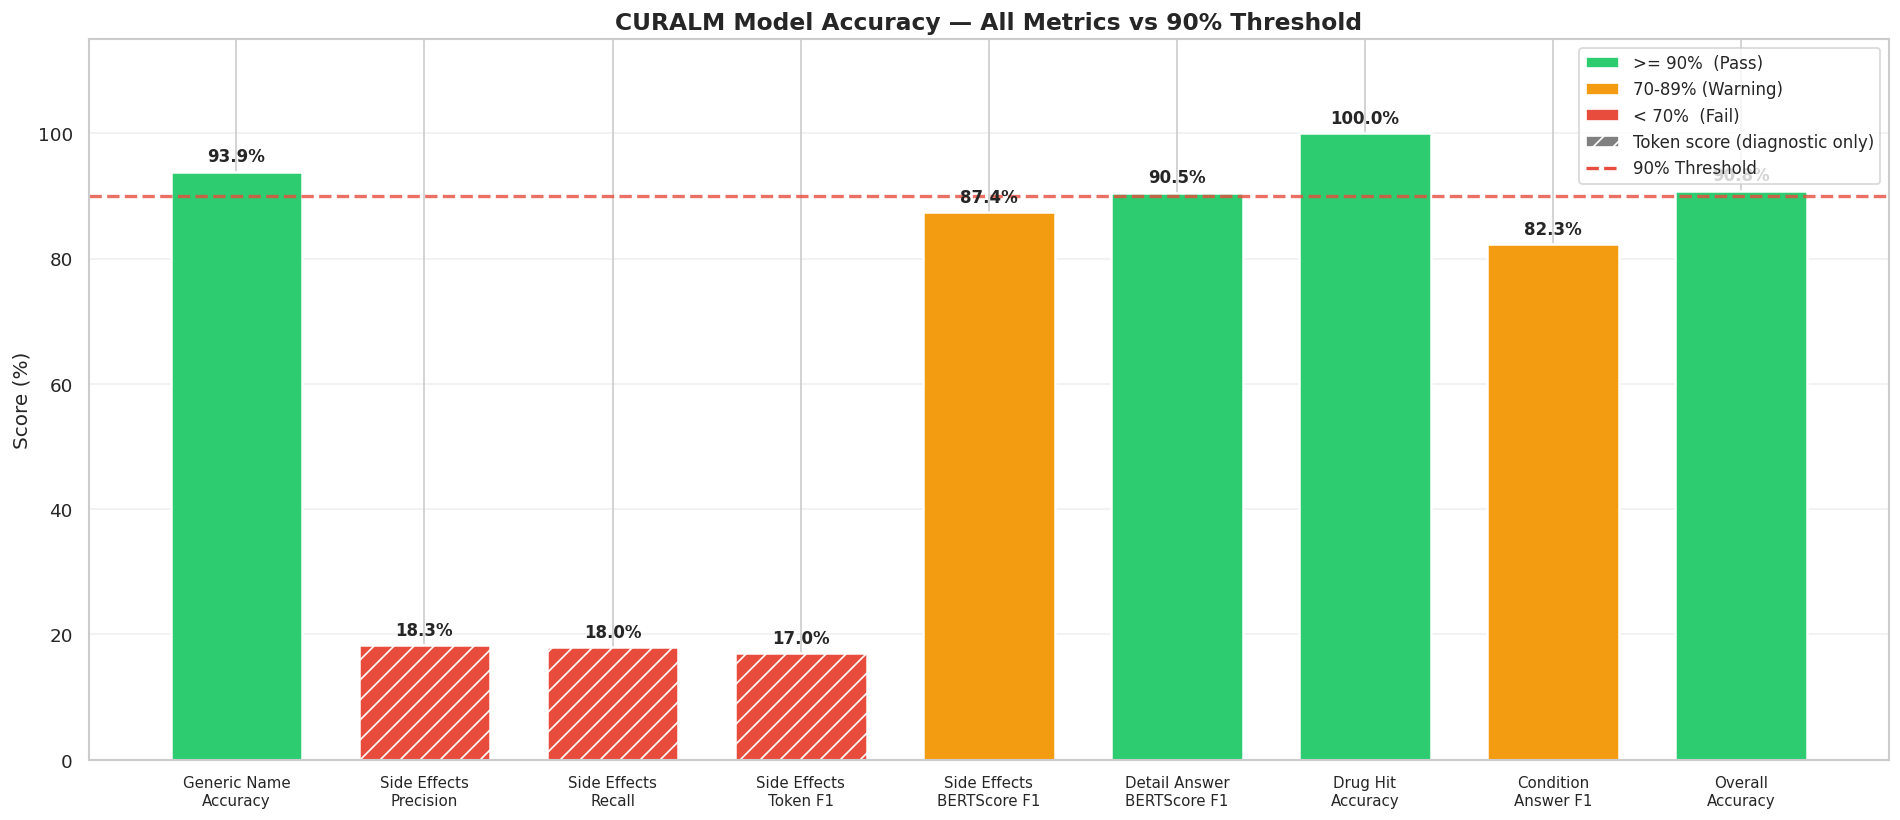

Saved: /content/curalm_plots/05_accuracy_dashboard.png


In [35]:
# Plot accuracy dashboard
# This chart compares all main evaluation scores with the 90% target.

import os
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# Make sure all needed metric variables already exist
required_metrics = [
    "generic_accuracy",
    "side_effects_precision",
    "side_effects_recall",
    "side_effects_f1",
    "bert_side_f1_mean",
    "bert_ans_f1_mean",
    "detail_answer_f1",
    "drug_hit_accuracy",
    "cond_answer_f1",
    "overall_accuracy",
]

missing_metrics = [
    metric_name
    for metric_name in required_metrics
    if metric_name not in globals()
]

if missing_metrics:
    raise RuntimeError(f"Missing variables: {missing_metrics}")


# Collect metrics for plotting
# Token scores are simple word-matching scores.
# BERTScore checks meaning similarity, so it is better for side effects.
score_table = {
    "Generic Name\nAccuracy": generic_accuracy,
    "Side Effects\nPrecision": side_effects_precision,
    "Side Effects\nRecall": side_effects_recall,
    "Side Effects\nToken F1": side_effects_f1,
    "Side Effects\nBERTScore F1": bert_side_f1_mean,
    "Detail Answer\nBERTScore F1": bert_ans_f1_mean,
    "Drug Hit\nAccuracy": drug_hit_accuracy,
    "Condition\nAnswer F1": cond_answer_f1,
    "Overall\nAccuracy": overall_accuracy,
}


metric_labels = list(score_table.keys())
metric_values = list(score_table.values())
metric_positions = range(len(metric_values))


# Mark token-based side effect metrics as diagnostic only
# يعني هذه المقاييس مساعدة، لكنها ليست المقياس الأساسي للأعراض الجانبية.
diagnostic_flags = [
    False,  # Generic accuracy
    True,   # Side effects precision
    True,   # Side effects recall
    True,   # Side effects token F1
    False,  # Side effects BERTScore F1
    False,  # Detail answer BERTScore F1
    False,  # Drug hit accuracy
    False,  # Condition answer F1
    False,  # Overall accuracy
]


# Choose bar colors based on score level
bar_colors = [
    "#2ecc71" if score >= 0.90
    else "#f39c12" if score >= 0.70
    else "#e74c3c"
    for score in metric_values
]


fig, chart = plt.subplots(figsize=(16, 7))

bars = chart.bar(
    metric_positions,
    [score * 100 for score in metric_values],
    color=bar_colors,
    edgecolor="white",
    linewidth=1.5,
    width=0.7,
    hatch=["//" if is_diag else "" for is_diag in diagnostic_flags],
)


# Add score value above each bar
for bar, score in zip(bars, metric_values):
    chart.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score * 100:.1f}%",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=10,
    )


# Add 90% target line
chart.axhline(
    y=90,
    color="#e74c3c",
    linestyle="--",
    linewidth=2,
    alpha=0.8
)


chart.set_xticks(metric_positions)
chart.set_xticklabels(metric_labels, fontsize=9)
chart.set_ylabel("Score (%)", fontsize=12)
chart.set_ylim(0, 115)
chart.set_title(
    "CURALM Model Accuracy — All Metrics vs 90% Threshold",
    fontsize=14,
    fontweight="bold"
)
chart.grid(axis="y", alpha=0.3)


# Explain colors and pattern in the legend
chart.legend(
    handles=[
        Patch(facecolor="#2ecc71", label=">= 90%  (Pass)"),
        Patch(facecolor="#f39c12", label="70-89% (Warning)"),
        Patch(facecolor="#e74c3c", label="< 70%  (Fail)"),
        Patch(facecolor="gray", hatch="//", label="Token score (diagnostic only)"),
        plt.Line2D(
            [0],
            [0],
            color="#e74c3c",
            linestyle="--",
            linewidth=2,
            label="90% Threshold"
        ),
    ],
    loc="upper right",
    fontsize=10,
)


plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "05_accuracy_dashboard.png"), dpi=150)
plt.show()

print(f"Saved: {PLOTS_DIR}/05_accuracy_dashboard.png")

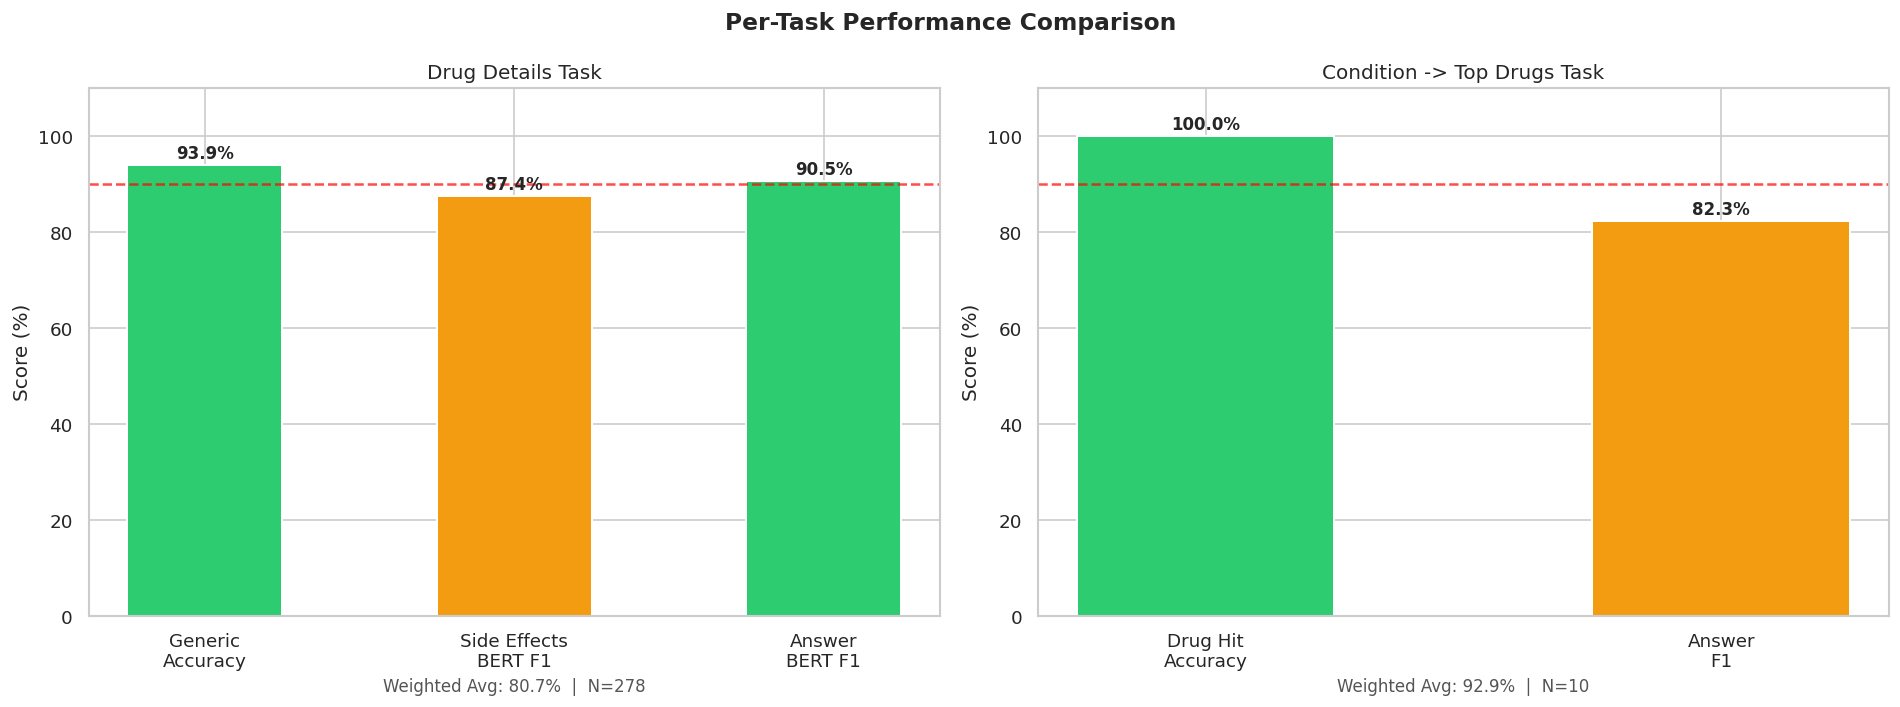

Saved: /content/curalm_plots/06_per_task_comparison.png


In [36]:
# Per-task performance comparison
# This chart compares the main scores for each task.

import os
import matplotlib.pyplot as plt


fig, charts = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Per-Task Performance Comparison", fontsize=14, fontweight="bold")


# Drug Details task scores
# This task checks if the model gives the correct generic name, side effects, and full answer.
drug_detail_scores = {
    "Generic\nAccuracy": generic_accuracy,
    "Side Effects\nBERT F1": bert_side_f1_mean,
    "Answer\nBERT F1": bert_ans_f1_mean,
}

drug_detail_labels = list(drug_detail_scores.keys())
drug_detail_values = list(drug_detail_scores.values())

# Choose bar color based on score level
# Green = pass, orange = medium, red = low.
drug_detail_colors = [
    "#2ecc71" if score >= 0.90
    else "#f39c12" if score >= 0.70
    else "#e74c3c"
    for score in drug_detail_values
]

drug_detail_bars = charts[0].bar(
    drug_detail_labels,
    [score * 100 for score in drug_detail_values],
    color=drug_detail_colors,
    edgecolor="white",
    linewidth=1.2,
    width=0.5,
)

# 90% target line
# هذا الخط يوضح الحد المطلوب، فإذا العمود فوقه يعني النتيجة وصلت للهدف.
charts[0].axhline(
    90,
    color="red",
    linestyle="--",
    alpha=0.7,
    linewidth=1.5
)

charts[0].set_title("Drug Details Task", fontsize=12)
charts[0].set_ylabel("Score (%)")
charts[0].set_ylim(0, 110)

# Write the score percentage above each bar
for bar, score in zip(drug_detail_bars, drug_detail_values):
    charts[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{score * 100:.1f}%",
        ha="center",
        fontsize=10,
        fontweight="bold",
    )

# Weighted average gives more importance to the main metrics.
# يعني مو كل المقاييس لها نفس الأهمية، نعطي وزن أكبر للمقاييس الأهم.
charts[0].set_xlabel(
    f"Weighted Avg: {detail_weighted * 100:.1f}%  |  N={len(detail_results_df)}",
    fontsize=10,
    color="#555555",
)


# Condition to Top Drugs task scores
# This task checks if the model suggests the correct top drugs for a medical condition.
condition_scores = {
    "Drug Hit\nAccuracy": drug_hit_accuracy,
    "Answer\nF1": cond_answer_f1,
}

condition_labels = list(condition_scores.keys())
condition_values = list(condition_scores.values())

# Use the same color rule for the second chart
condition_colors = [
    "#2ecc71" if score >= 0.90
    else "#f39c12" if score >= 0.70
    else "#e74c3c"
    for score in condition_values
]

condition_bars = charts[1].bar(
    condition_labels,
    [score * 100 for score in condition_values],
    color=condition_colors,
    edgecolor="white",
    linewidth=1.2,
    width=0.5,
)

# 90% target line
# نفس الخط هنا يوضح هل نتائج مهمة اقتراح الأدوية وصلت للهدف أو لا.
charts[1].axhline(
    90,
    color="red",
    linestyle="--",
    alpha=0.7,
    linewidth=1.5
)

charts[1].set_title("Condition -> Top Drugs Task", fontsize=12)
charts[1].set_ylabel("Score (%)")
charts[1].set_ylim(0, 110)

# Write the score percentage above each bar
for bar, score in zip(condition_bars, condition_values):
    charts[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{score * 100:.1f}%",
        ha="center",
        fontsize=10,
        fontweight="bold",
    )

# Show weighted average and number of tested samples
# N يعني عدد الأمثلة اللي اختبرنا عليها هذا الجزء.
charts[1].set_xlabel(
    f"Weighted Avg: {cond_weighted * 100:.1f}%  |  N={len(cond_results_df)}",
    fontsize=10,
    color="#555555",
)


plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "06_per_task_comparison.png"), dpi=150)
plt.show()

print(f"Saved: {PLOTS_DIR}/06_per_task_comparison.png")

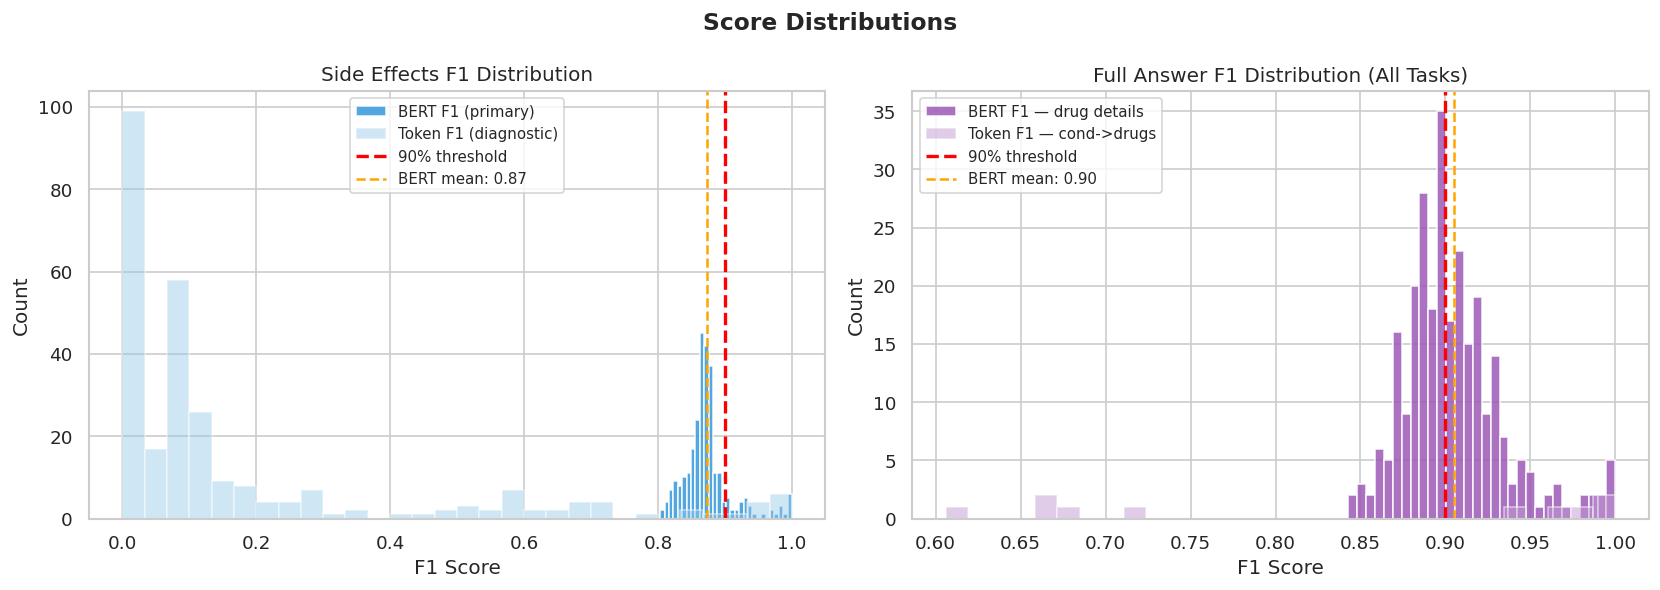

Saved: /content/curalm_plots/07_score_distributions.png


In [37]:
# Score distributions
# Compare primary BERTScore with simple token F1.
# BERTScore يقارن المعنى، وToken F1 يقارن تطابق الكلمات.

fig, charts = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Score Distributions", fontsize=14, fontweight="bold")


# Side effects scores
side_bert = detail_results_df["bert_side_f1"]
side_token = detail_results_df["side_f1"]

charts[0].hist(
    side_bert,
    bins=30,
    color="#3498db",
    edgecolor="white",
    alpha=0.85,
    label="BERT F1 (primary)",
)

charts[0].hist(
    side_token,
    bins=30,
    color="#95c8e8",
    edgecolor="white",
    alpha=0.45,
    label="Token F1 (diagnostic)",
)

charts[0].axvline(
    0.90,
    color="red",
    linestyle="--",
    linewidth=2,
    label="90% threshold",
)

charts[0].axvline(
    side_bert.mean(),
    color="orange",
    linestyle="--",
    label=f"BERT mean: {side_bert.mean():.2f}",
)

charts[0].set_title("Side Effects F1 Distribution")
charts[0].set_xlabel("F1 Score")
charts[0].set_ylabel("Count")
charts[0].legend(fontsize=9)


# Full answer scores
answer_bert = detail_results_df["bert_ans_f1"]
condition_answer = cond_results_df["answer_f1"]

charts[1].hist(
    answer_bert,
    bins=30,
    color="#9b59b6",
    edgecolor="white",
    alpha=0.85,
    label="BERT F1 — drug details",
)

charts[1].hist(
    condition_answer,
    bins=30,
    color="#c39bd3",
    edgecolor="white",
    alpha=0.50,
    label="Token F1 — cond->drugs",
)

charts[1].axvline(
    0.90,
    color="red",
    linestyle="--",
    linewidth=2,
    label="90% threshold",
)

charts[1].axvline(
    answer_bert.mean(),
    color="orange",
    linestyle="--",
    label=f"BERT mean: {answer_bert.mean():.2f}",
)

charts[1].set_title("Full Answer F1 Distribution (All Tasks)")
charts[1].set_xlabel("F1 Score")
charts[1].set_ylabel("Count")
charts[1].legend(fontsize=9)


plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "07_score_distributions.png"), dpi=150)
plt.show()

print(f"Saved: {PLOTS_DIR}/07_score_distributions.png")

Showing 15 / 41 conditions (lowest by BERT Answer F1)


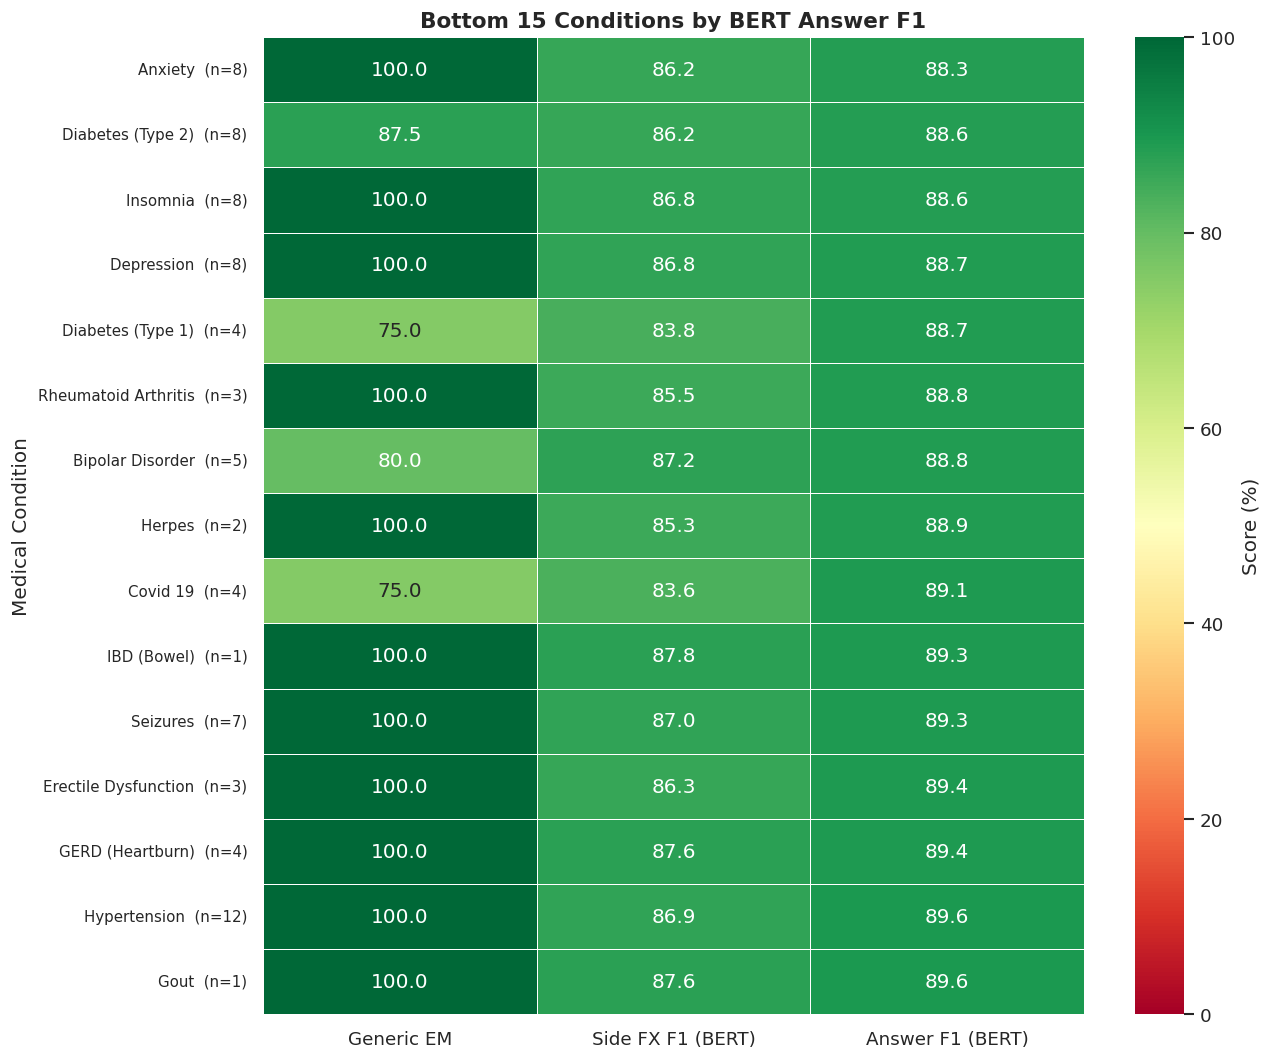

Saved: /content/curalm_plots/08_error_analysis_heatmap.png


In [38]:
# Error analysis
# This heatmap shows the lowest-performing medical conditions.

if len(detail_results_df) > 0:
    condition_scores = (
        detail_results_df
        .groupby("condition")
        .agg(
            generic_em=("generic_em", "mean"),
            side_bert_f1=("bert_side_f1", "mean"),
            answer_bert_f1=("bert_ans_f1", "mean"),
            sample_count=("bert_ans_f1", "count"),
        )
        .sort_values("answer_bert_f1", ascending=True)
    )

    lowest_conditions = condition_scores.head(15)
    shown_count = len(lowest_conditions)

    print(
        f"Showing {shown_count} / {len(condition_scores)} conditions "
        f"(lowest by BERT Answer F1)"
    )

    # Prepare heatmap values as percentages
    heatmap_values = lowest_conditions[
        ["generic_em", "side_bert_f1", "answer_bert_f1"]
    ].copy() * 100

    heatmap_values.columns = [
        "Generic EM",
        "Side FX F1 (BERT)",
        "Answer F1 (BERT)",
    ]

    # Add sample count beside each condition name
    # n يعني عدد الأمثلة المستخدمة لكل حالة طبية.
    heatmap_values.index = [
        f"{condition}  (n={lowest_conditions.loc[condition, 'sample_count']})"
        for condition in lowest_conditions.index
    ]

    fig, chart = plt.subplots(figsize=(11, max(6, shown_count * 0.6)))

    # Heatmap makes weak and strong conditions easier to compare.
    # اللون يساعدنا نعرف بسرعة الحالات الضعيفة والقوية.
    sns.heatmap(
        heatmap_values,
        annot=True,
        fmt=".1f",
        cmap="RdYlGn",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        ax=chart,
        cbar_kws={"label": "Score (%)"},
    )

    chart.set_title(
        f"Bottom {shown_count} Conditions by BERT Answer F1",
        fontsize=13,
        fontweight="bold",
    )

    chart.set_ylabel("Medical Condition")
    chart.tick_params(axis="y", labelsize=9)

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "08_error_analysis_heatmap.png"), dpi=150)
    plt.show()

    print(f"Saved: {PLOTS_DIR}/08_error_analysis_heatmap.png")

else:
    print("WARNING: detail_results_df is empty — skipping heatmap")

## 14. Sample Predictions & Error Analysis


In [39]:
# Sample predictions
# This cell shows examples from weak, middle, and strong predictions.

def safe_text(value, max_chars=100):
    # Avoid printing NaN or None values from parsing results.
    if value is None or str(value) == "nan":
        return "<empty>"

    return str(value)[:max_chars]


def get_sample_rows(data, score_column, n=2):
    # Select worst, random middle, and best rows for a balanced sample.
    # يعني ما نعرض أفضل النتائج فقط، نعرض الضعيف والمتوسط والقوي.

    if len(data) <= n * 2:
        return data

    best_rows = data.nlargest(n, score_column)
    worst_rows = data.nsmallest(n, score_column)

    middle_rows = data.drop(
        index=best_rows.index.tolist() + worst_rows.index.tolist()
    )

    random_middle_rows = middle_rows.sample(
        min(n, len(middle_rows)),
        random_state=42
    )

    sample_rows = pd.concat([
        worst_rows,
        random_middle_rows,
        best_rows
    ])

    return sample_rows[~sample_rows.index.duplicated(keep="first")]


# Drug Details Task samples
print("=" * 80)
print("SAMPLE PREDICTIONS — Drug Details Task")
print("=" * 80)

detail_samples = get_sample_rows(
    detail_results_df,
    "bert_ans_f1",
    n=2
)

for _, row in detail_samples.iterrows():
    status = "PASS" if row["generic_em"] == 1 and row["bert_side_f1"] >= 0.8 else "FAIL"

    print(f"\n{status} [{row['condition']}] -> {row['drug']}")
    print(f"  GOLD generic : {safe_text(row['gold_generic'], 80)}")
    print(f"  PRED generic : {safe_text(row['pred_generic'], 80)}  (EM: {row['generic_em']})")
    print(f"  GOLD side fx : {safe_text(row['gold_side'], 120)}")
    print(f"  PRED side fx : {safe_text(row['pred_side'], 120)}")

    print(
        f"  Side F1 BERT : {row['bert_side_f1']:.3f} (primary)  "
        f"Token: {row['side_f1']:.3f} (diagnostic)"
    )

    print(
        f"  Answer F1    : {row['bert_ans_f1']:.3f} (BERT)  "
        f"Token: {row['answer_f1']:.3f}"
    )


# Condition to Top Drugs Task samples
print("\n" + "=" * 80)
print("SAMPLE PREDICTIONS — Condition -> Top Drugs Task")
print("=" * 80)

condition_samples = get_sample_rows(
    cond_results_df,
    "answer_f1",
    n=2
)

for _, row in condition_samples.iterrows():
    status = "PASS" if row["drug_hit"] == 1 else "FAIL"

    print(f"\n{status} [{row['condition']}]")
    print(f"  GOLD drugs : {row['gold_drugs'][:5]}")
    print(f"  PRED drugs : {row['pred_drugs'][:5]}")
    print(f"  Drug Hit   : {row['drug_hit']}  |  Answer F1: {row['answer_f1']:.3f}")

print("\n" + "=" * 80)

SAMPLE PREDICTIONS — Drug Details Task

FAIL [Osteoarthritis] -> Motrin IB
  GOLD generic : ibuprofen 200mg
  PRED generic : ibuprofen (oral route)  (EM: 0)
  GOLD side fx : changes in your vision, srt_brth (even with mild exertion), swl or rapid wgt_gain, a skn_rsh, no matter how mild
  PRED side fx : Although not all of these side effects may occur, if they do occur they may need medical attention Check with your docto
  Side F1 BERT : 0.813 (primary)  Token: 0.149 (diagnostic)
  Answer F1    : 0.843 (BERT)  Token: 0.261

PASS [Diabetes (Type 2)] -> Glucotrol
  GOLD generic : glipizide
  PRED generic : glipizide (oral route)  (EM: 1)
  GOLD side fx : diar, cnst, gas, diz, drws
  PRED side fx : Although not all of these side effects may occur, if they do occur they may need medical attention Check with your docto
  Side F1 BERT : 0.812 (primary)  Token: 0.000 (diagnostic)
  Answer F1    : 0.844 (BERT)  Token: 0.114

PASS [Osteoporosis] -> Premarin
  GOLD generic : conjugated estrogens

In [40]:
# Error analysis: worst predictions
# This cell prints the weakest side-effect predictions and generic name mismatches.

print("=" * 70)
print("TOP-10 WORST PREDICTIONS BY SIDE EFFECTS F1 (BERT)")
print("=" * 70)


# Get the 10 lowest side-effect BERT F1 scores
worst_side_effects = detail_results_df.nsmallest(10, "bert_side_f1")

for _, row in worst_side_effects.iterrows():
    print(f"\n[{row['condition']}] {row['drug']}")

    print(
        f"BERT F1={row['bert_side_f1']:.3f}  "
        f"Token F1={row['side_f1']:.3f}  "
        f"P={row['side_precision']:.3f}  "
        f"R={row['side_recall']:.3f}"
    )

    # BERT F1 compares meaning, while Token F1 compares exact word overlap.
    # يعني هنا نقدر نشوف هل المشكلة في المعنى أو بس اختلاف كلمات.
    print(f"GOLD: {safe_text(row['gold_side'], 120)}")
    print(f"PRED: {safe_text(row['pred_side'], 120)}")


print("\n" + "=" * 70)
print("GENERIC NAME MISMATCHES")
print("=" * 70)


# Show rows where predicted generic name did not match the correct one
generic_mismatches = detail_results_df[detail_results_df["generic_em"] == 0]

print(f"Total mismatches: {len(generic_mismatches)} / {len(detail_results_df)}")


for _, row in generic_mismatches.head(15).iterrows():
    print(f"\n[{row['condition']}] {row['drug']}")
    print(f"GOLD: {safe_text(row['gold_generic'], 80)}")
    print(f"PRED: {safe_text(row['pred_generic'], 80)}")

TOP-10 WORST PREDICTIONS BY SIDE EFFECTS F1 (BERT)

[Diabetes (Type 1)] insulin degludec
BERT F1=0.803  Token F1=0.000  P=0.000  R=0.000
GOLD: Taking certain diabetes pills called thiazolidinediones or “TZDs” with insulin degludec may cause heart failure in some 
PRED: hives, difficult breathing, swelling of your face, lips, tongue

[Cholesterol] evolocumab
BERT F1=0.806  Token F1=0.000  P=0.000  R=0.000
GOLD: run_nos, sor_thr, symptoms of the common cold, flu or flu-like symptoms, bk_pn
PRED: Serious Allergic Reactions, hive

[Diabetes (Type 2)] Glucotrol
BERT F1=0.812  Token F1=0.000  P=0.000  R=0.000
GOLD: diar, cnst, gas, diz, drws
PRED: Although not all of these side effects may occur, if they do occur they may need medical attention Check with your docto

[Osteoarthritis] Motrin IB
BERT F1=0.813  Token F1=0.149  P=0.090  R=0.435
GOLD: changes in your vision, srt_brth (even with mild exertion), swl or rapid wgt_gain, a skn_rsh, no matter how mild
PRED: Although not all of these si

## 15. Save Final Report & All Metrics


In [41]:
# Save comprehensive report
# This cell stores the final model settings, losses, and evaluation scores in one JSON file.

import os
import json


def safe_round(value, digits=4):
    # Convert values to rounded numbers when possible.
    # يفيد إذا كانت القيمة فاضية أو مو رقم عشان ما يوقف الكود.
    try:
        return round(float(value), digits)
    except (TypeError, ValueError):
        return None


def get_metric_value(metrics_dict, metric_name):
    # Read one metric safely from a metrics dictionary.
    if metrics_dict is None:
        return None

    return safe_round(metrics_dict.get(metric_name))


# Use available validation and test metrics
validation_metrics = val_metrics if "val_metrics" in globals() else {}
testing_metrics = test_metrics if "test_metrics" in globals() else {}


# Select the trainer that was actually used
active_trainer = None

if "full_trainer" in globals():
    active_trainer = full_trainer
elif "trainer" in globals():
    active_trainer = trainer


# Collect model settings
report_model_name = model_name if "model_name" in globals() else MODEL_ID
report_max_length = max_length if "max_length" in globals() else MAX_LENGTH

if "lora_settings" in globals():
    lora_used = lora_settings
elif "lora_config" in globals():
    lora_used = lora_config
else:
    lora_used = None

lora_rank = lora_used.r if lora_used is not None else "N/A"
lora_alpha = lora_used.lora_alpha if lora_used is not None else "N/A"

report_learning_rate = training_args.learning_rate if "training_args" in globals() else "N/A"
report_epochs = epochs if "epochs" in globals() else "N/A"


# Get best evaluation loss if it exists
best_eval_loss = None

if active_trainer is not None and hasattr(active_trainer, "state"):
    if active_trainer.state.best_metric is not None:
        best_eval_loss = safe_round(active_trainer.state.best_metric)


def summarize_results(detail_df, condition_df):
    # Create a compact summary for one evaluation strategy.

    generic_accuracy = safe_round(detail_df["generic_em"].mean())
    side_precision = safe_round(detail_df["side_precision"].mean())
    side_recall = safe_round(detail_df["side_recall"].mean())
    side_token_f1 = safe_round(detail_df["side_f1"].mean())

    side_bert_f1 = safe_round(detail_df["bert_side_f1"].mean())
    answer_bert_f1 = safe_round(detail_df["bert_ans_f1"].mean())
    detail_answer_f1 = safe_round(detail_df["answer_f1"].mean())

    drug_hit_accuracy = safe_round(condition_df["drug_hit"].mean())
    condition_answer_f1 = safe_round(condition_df["answer_f1"].mean())

    detail_macro = safe_round(
        (detail_df["generic_em"].mean() + detail_df["bert_side_f1"].mean()) / 2
    )

    overall_accuracy = safe_round(
        (
            detail_df["generic_em"].mean()
            + detail_df["bert_side_f1"].mean()
            + condition_df["drug_hit"].mean()
        ) / 3
    )

    return {
        "generic_name_accuracy_em": generic_accuracy,
        "side_effects_precision": side_precision,
        "side_effects_recall": side_recall,
        "side_effects_f1_token": side_token_f1,
        "bert_side_f1": side_bert_f1,
        "full_answer_f1_detail": detail_answer_f1,
        "bert_answer_f1_detail": answer_bert_f1,
        "drug_hit_accuracy": drug_hit_accuracy,
        "full_answer_f1_condition": condition_answer_f1,
        "macro_detail": detail_macro,
        "overall_accuracy": overall_accuracy,
        "meets_90_threshold": bool(overall_accuracy >= 0.90),
        "n_detail_samples": int(len(detail_df)),
        "n_cond_samples": int(len(condition_df)),
    }


# Build summaries for both evaluation strategies
with_rag_summary = summarize_results(detail_results_df_rag, cond_results_df_rag)
without_rag_summary = summarize_results(detail_results_df_norag, cond_results_df_norag)


# Compare the two strategies
comparison_keys = [
    "generic_name_accuracy_em",
    "side_effects_f1_token",
    "bert_side_f1",
    "full_answer_f1_detail",
    "drug_hit_accuracy",
    "overall_accuracy",
]

score_difference = {}

for metric_name in comparison_keys:
    if (
        with_rag_summary.get(metric_name) is not None
        and without_rag_summary.get(metric_name) is not None
    ):
        # Difference = with-RAG score minus without-RAG score.
        # الفرق الموجب يعني الاستراتيجية الأولى أفضل في هذا المقياس.
        score_difference[metric_name] = safe_round(
            with_rag_summary[metric_name] - without_rag_summary[metric_name]
        )

rag_improves_overall = bool(score_difference.get("overall_accuracy", 0) > 0)


# Final report content
model_report = {
    "model_info": {
        "base_model": report_model_name,
        "adapter": "QLoRA",
        "lora_r": lora_rank,
        "lora_alpha": lora_alpha,
        "max_length": report_max_length,
        "num_epochs": report_epochs,
        "learning_rate": report_learning_rate,
    },

    "loss_metrics": {
        "best_eval_loss": best_eval_loss,
        "val_loss": get_metric_value(validation_metrics, "eval_loss"),
        "test_loss": get_metric_value(testing_metrics, "test_loss"),
        "val_perplexity": get_metric_value(validation_metrics, "eval_perplexity"),
        "test_perplexity": get_metric_value(testing_metrics, "test_perplexity"),
    },

    "results_with_rag": with_rag_summary,
    "results_without_rag": without_rag_summary,

    "rag_comparison": {
        "rag_improves_overall": rag_improves_overall,
        "delta_overall_accuracy": score_difference.get("overall_accuracy"),
        "delta_generic_em": score_difference.get("generic_name_accuracy_em"),
        "delta_side_f1_token": score_difference.get("side_effects_f1_token"),
        "delta_bert_side_f1": score_difference.get("bert_side_f1"),
        "delta_answer_f1": score_difference.get("full_answer_f1_detail"),
        "delta_drug_hit": score_difference.get("drug_hit_accuracy"),
        "interpretation": (
            "RAG improves overall accuracy. Retrieval context is beneficial."
            if rag_improves_overall
            else "RAG does not improve overall accuracy. Retrieval quality may need improvement."
        ),
    },

    "overall": {
        "overall_accuracy": with_rag_summary["overall_accuracy"],
        "meets_90_threshold": with_rag_summary["meets_90_threshold"],
    },
}


# Save JSON report
report_folder = BASE_DIR if "BASE_DIR" in globals() else main_folder
report_path = os.path.join(report_folder, "model_report.json")

with open(report_path, "w") as file:
    json.dump(model_report, file, indent=2)

print("Full model report saved:", report_path)
print(json.dumps(model_report, indent=2))

Full model report saved: /content/curalm_project/model_report.json
{
  "model_info": {
    "base_model": "BioMistral/BioMistral-7B-DARE",
    "adapter": "QLoRA",
    "lora_r": 32,
    "lora_alpha": 64,
    "max_length": 1536,
    "num_epochs": 4,
    "learning_rate": 5e-05
  },
  "loss_metrics": {
    "best_eval_loss": 0.3771,
    "val_loss": 0.3771,
    "test_loss": 0.3897,
    "val_perplexity": 1.458,
    "test_perplexity": 1.4766
  },
  "results_with_rag": {
    "generic_name_accuracy_em": 0.9388,
    "side_effects_precision": 0.1831,
    "side_effects_recall": 0.1798,
    "side_effects_f1_token": 0.1697,
    "bert_side_f1": 0.8736,
    "full_answer_f1_detail": 0.4082,
    "bert_answer_f1_detail": 0.905,
    "drug_hit_accuracy": 0.9,
    "full_answer_f1_condition": 0.4021,
    "macro_detail": 0.9062,
    "overall_accuracy": 0.9042,
    "meets_90_threshold": true,
    "n_detail_samples": 278,
    "n_cond_samples": 10
  },
  "results_without_rag": {
    "generic_name_accuracy_em": 0.6

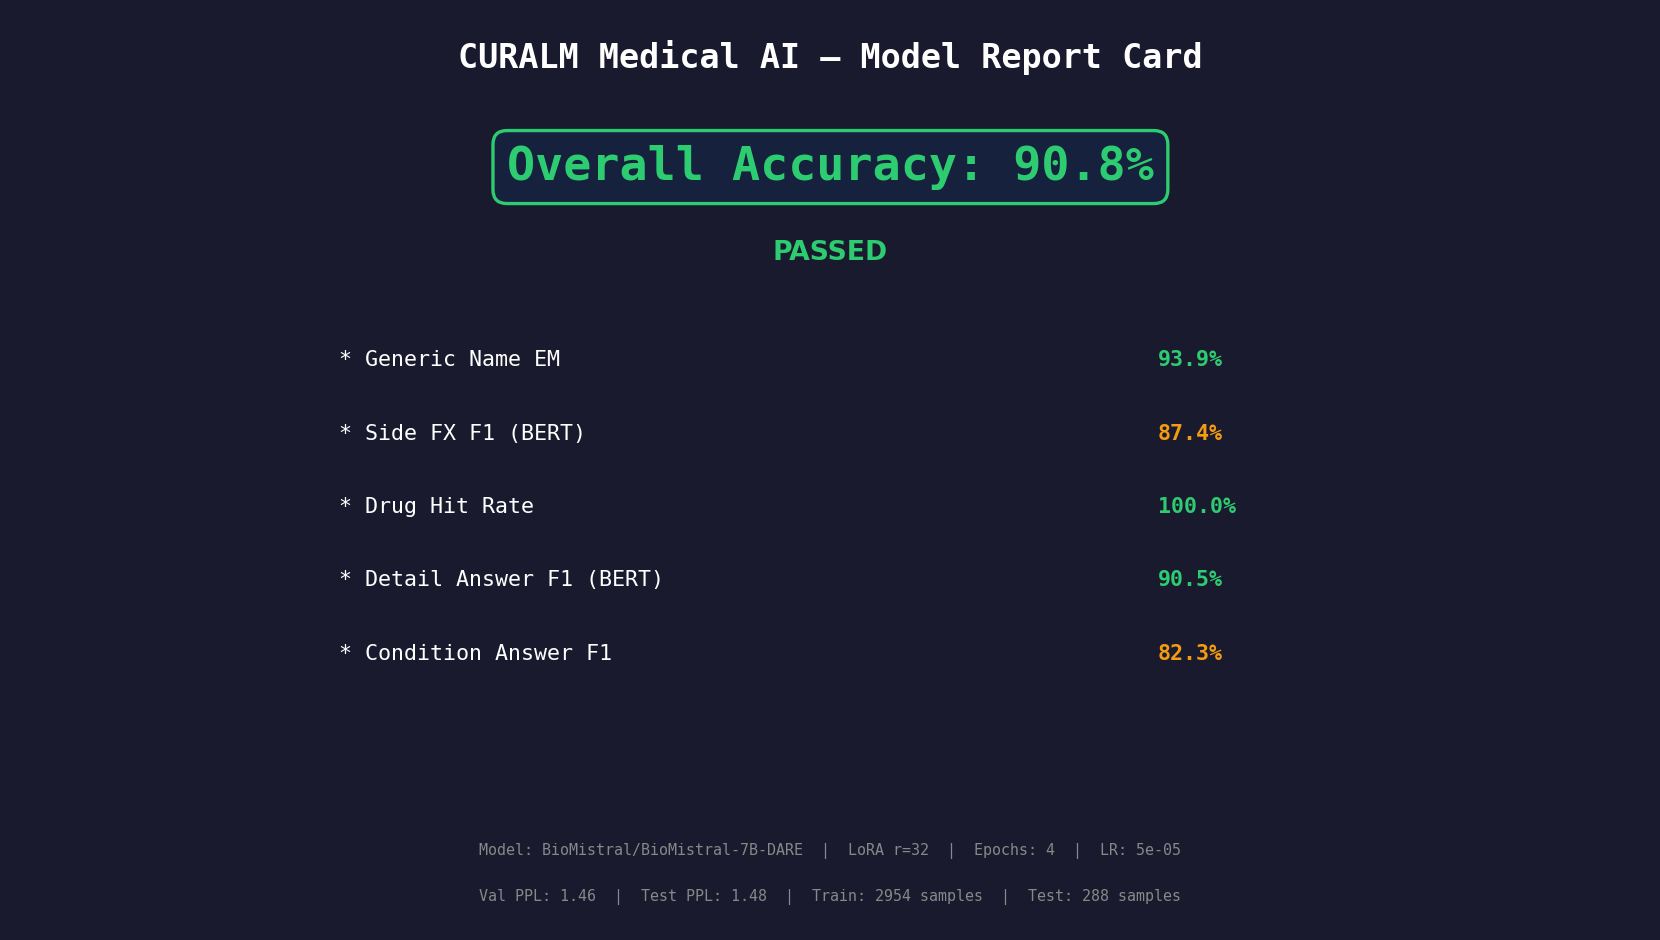

Saved: /content/curalm_plots/09_report_card.png


In [45]:
import matplotlib.pyplot as plt
import os

# Summary Plot
# This report card gives a quick visual summary of the final model results.

def format_perplexity(metrics_dict, metric_name):
    # Return a clean perplexity value or N/A if missing.
    try:
        return f"{float(metrics_dict.get(metric_name)):.2f}"
    except (TypeError, ValueError, AttributeError):
        return "N/A"


# Use available report values
report_model_name = model_name if "model_name" in globals() else MODEL_ID
report_lora_rank = lora_rank if "lora_rank" in globals() else _lora_r if "_lora_r" in globals() else "N/A"
report_epochs = epochs if "epochs" in globals() else _epochs if "_epochs" in globals() else "N/A"
report_learning_rate = (
    learning_rate if "learning_rate" in globals()
    else _lr if "_lr" in globals()
    else "N/A"
)

validation_metrics = val_metrics if "val_metrics" in globals() else {}
testing_metrics = test_metrics if "test_metrics" in globals() else {}


fig = plt.figure(figsize=(14, 8))
fig.patch.set_facecolor("#1a1a2e")

chart = fig.add_subplot(111)
chart.set_xlim(0, 10)
chart.set_ylim(0, 10)
chart.axis("off")
chart.set_facecolor("#1a1a2e")


# Main title
chart.text(
    5,
    9.5,
    "CURALM Medical AI — Model Report Card",
    fontsize=20,
    color="white",
    fontweight="bold",
    ha="center",
    va="center",
    fontfamily="monospace"
)


# Overall score color
score_color = (
    "#2ecc71" if overall_accuracy >= 0.90
    else "#f39c12" if overall_accuracy >= 0.70
    else "#e74c3c"
)

chart.text(
    5,
    8.3,
    f"Overall Accuracy: {overall_accuracy * 100:.1f}%",
    fontsize=28,
    color=score_color,
    fontweight="bold",
    ha="center",
    va="center",
    fontfamily="monospace",
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="#16213e",
        edgecolor=score_color,
        linewidth=2
    )
)


# Model status based on target score
# إذا النتيجة 90% أو أكثر يعتبر النموذج وصل للهدف المطلوب.
status = "PASSED" if overall_accuracy >= 0.90 else "NEEDS IMPROVEMENT"

chart.text(
    5,
    7.3,
    status,
    fontsize=16,
    color=score_color,
    ha="center",
    fontweight="bold"
)


# Main metrics shown in the report card
report_rows = [
    ("Generic Name EM", f"{generic_accuracy * 100:.1f}%", generic_accuracy),
    ("Side FX F1 (BERT)", f"{bert_side_f1_mean * 100:.1f}%", bert_side_f1_mean),
    ("Drug Hit Rate", f"{drug_hit_accuracy * 100:.1f}%", drug_hit_accuracy),
    ("Detail Answer F1 (BERT)", f"{bert_ans_f1_mean * 100:.1f}%", bert_ans_f1_mean),
    ("Condition Answer F1", f"{cond_answer_f1 * 100:.1f}%", cond_answer_f1),
]

start_y = 6.2

for index, (metric_name, metric_value, metric_score) in enumerate(report_rows):
    y_position = start_y - index * 0.8

    row_color = (
        "#2ecc71" if metric_score >= 0.90
        else "#f39c12" if metric_score >= 0.70
        else "#e74c3c"
    )

    chart.text(
        2,
        y_position,
        f"* {metric_name}",
        fontsize=13,
        color="white",
        va="center",
        fontfamily="monospace"
    )

    chart.text(
        7,
        y_position,
        metric_value,
        fontsize=13,
        color=row_color,
        va="center",
        fontweight="bold",
        fontfamily="monospace"
    )


# Model settings summary
chart.text(
    5,
    0.8,
    f"Model: {report_model_name}  |  LoRA r={report_lora_rank}  |  "
    f"Epochs: {report_epochs}  |  LR: {report_learning_rate}",
    fontsize=9,
    color="#888",
    ha="center",
    fontfamily="monospace"
)


# Perplexity and data size summary
# PPL أقل يعني النموذج يتوقع النصوص بشكل أفضل.
chart.text(
    5,
    0.3,
    f"Val PPL: {format_perplexity(validation_metrics, 'eval_perplexity')}  |  "
    f"Test PPL: {format_perplexity(testing_metrics, 'test_perplexity')}  |  "
    f"Train: {len(train_df)} samples  |  Test: {len(test_df)} samples",
    fontsize=9,
    color="#888",
    ha="center",
    fontfamily="monospace"
)


plt.tight_layout()
plt.savefig(
    os.path.join(PLOTS_DIR, "09_report_card.png"),
    facecolor="#1a1a2e",
    dpi=150
)
plt.show()

print(f"Saved: {PLOTS_DIR}/09_report_card.png")

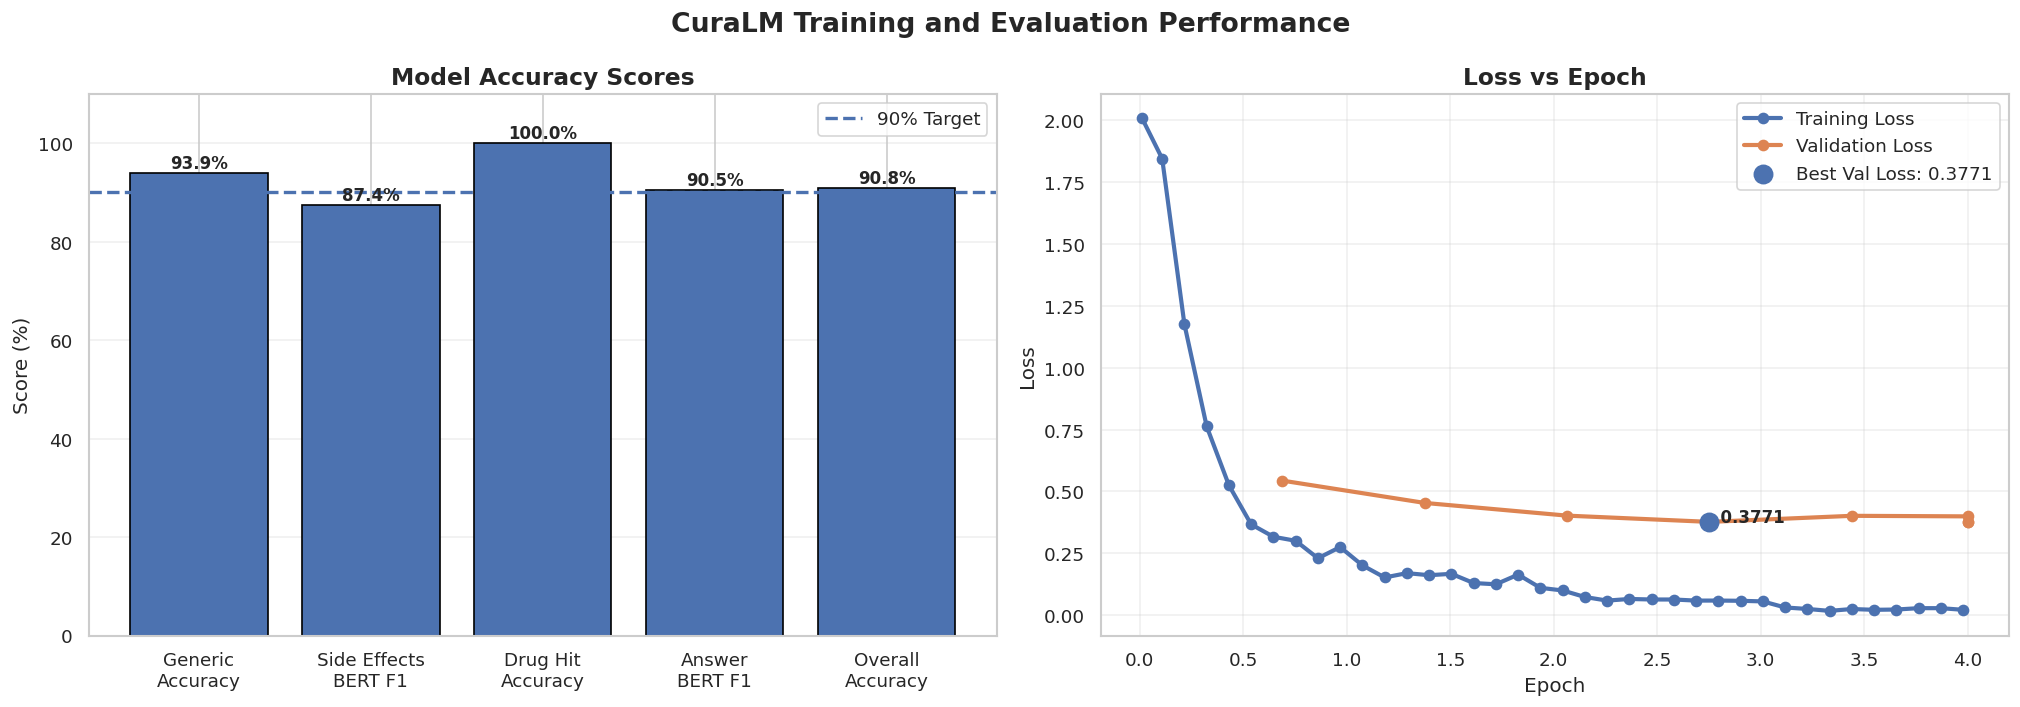

Saved plot at: /content/curalm_required_plots/accuracy_and_loss_plot.png


In [44]:
# Accuracy vs Epoch + Loss vs Epoch

import os
import numpy as np
import matplotlib.pyplot as plt

SAVE_DIR = "/content/curalm_required_plots"
os.makedirs(SAVE_DIR, exist_ok=True)

# Make sure trainer exists
if "full_trainer" not in globals():
    raise RuntimeError("full_trainer not found. Run the full training cell first.")

# Make sure accuracy metrics exist
if "overall_accuracy" not in globals():
    raise RuntimeError("overall_accuracy not found. Run Cell 42 and Cell 43 before this plot.")

logs = full_trainer.state.log_history

if len(logs) == 0:
    raise RuntimeError("Training logs are empty. Run the training cell first.")

# Calculate steps per epoch
if "steps_per_epoch" not in globals():
    steps_per_epoch = np.ceil(
        len(tokenized_train) /
        (
            full_trainer.args.per_device_train_batch_size
            * full_trainer.args.gradient_accumulation_steps
        )
    )

def step_to_epoch(step):
    return step / steps_per_epoch


# ----------------------------
# Extract training loss
# ----------------------------
train_loss_epochs = []
train_loss_values = []

for log in logs:
    if "loss" in log and "eval_loss" not in log and "step" in log:
        train_loss_epochs.append(step_to_epoch(log["step"]))
        train_loss_values.append(log["loss"])



# Extract validation loss

eval_loss_epochs = []
eval_loss_values = []

for log in logs:
    if "eval_loss" in log and "step" in log:
        eval_loss_epochs.append(step_to_epoch(log["step"]))
        eval_loss_values.append(log["eval_loss"])



accuracy_labels = [
    "Generic\nAccuracy",
    "Side Effects\nBERT F1",
    "Drug Hit\nAccuracy",
    "Answer\nBERT F1",
    "Overall\nAccuracy"
]

accuracy_values = [
    generic_accuracy * 100,
    bert_side_f1_mean * 100,
    drug_hit_accuracy * 100,
    bert_ans_f1_mean * 100,
    overall_accuracy * 100
]




fig, axes = plt.subplots(1, 2, figsize=(17, 6))


bars = axes[0].bar(
    accuracy_labels,
    accuracy_values,
    edgecolor="black",
    linewidth=1
)

axes[0].axhline(
    90,
    linestyle="--",
    linewidth=2,
    label="90% Target"
)

for bar, value in zip(bars, accuracy_values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

axes[0].set_title("Model Accuracy Scores", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Score (%)")
axes[0].set_ylim(0, 110)
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend()


if len(train_loss_values) > 0:
    axes[1].plot(
        train_loss_epochs,
        train_loss_values,
        marker="o",
        linewidth=2.5,
        label="Training Loss"
    )

if len(eval_loss_values) > 0:
    axes[1].plot(
        eval_loss_epochs,
        eval_loss_values,
        marker="o",
        linewidth=2.5,
        label="Validation Loss"
    )

    best_index = int(np.argmin(eval_loss_values))
    best_epoch = eval_loss_epochs[best_index]
    best_loss = eval_loss_values[best_index]

    axes[1].scatter(
        best_epoch,
        best_loss,
        s=120,
        zorder=5,
        label=f"Best Val Loss: {best_loss:.4f}"
    )

    axes[1].text(
        best_epoch,
        best_loss,
        f"  {best_loss:.4f}",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_title("Loss vs Epoch", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.suptitle("CuraLM Training and Evaluation Performance", fontsize=16, fontweight="bold")
plt.tight_layout()

plot_path = os.path.join(SAVE_DIR, "accuracy_and_loss_plot.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved plot at:", plot_path)

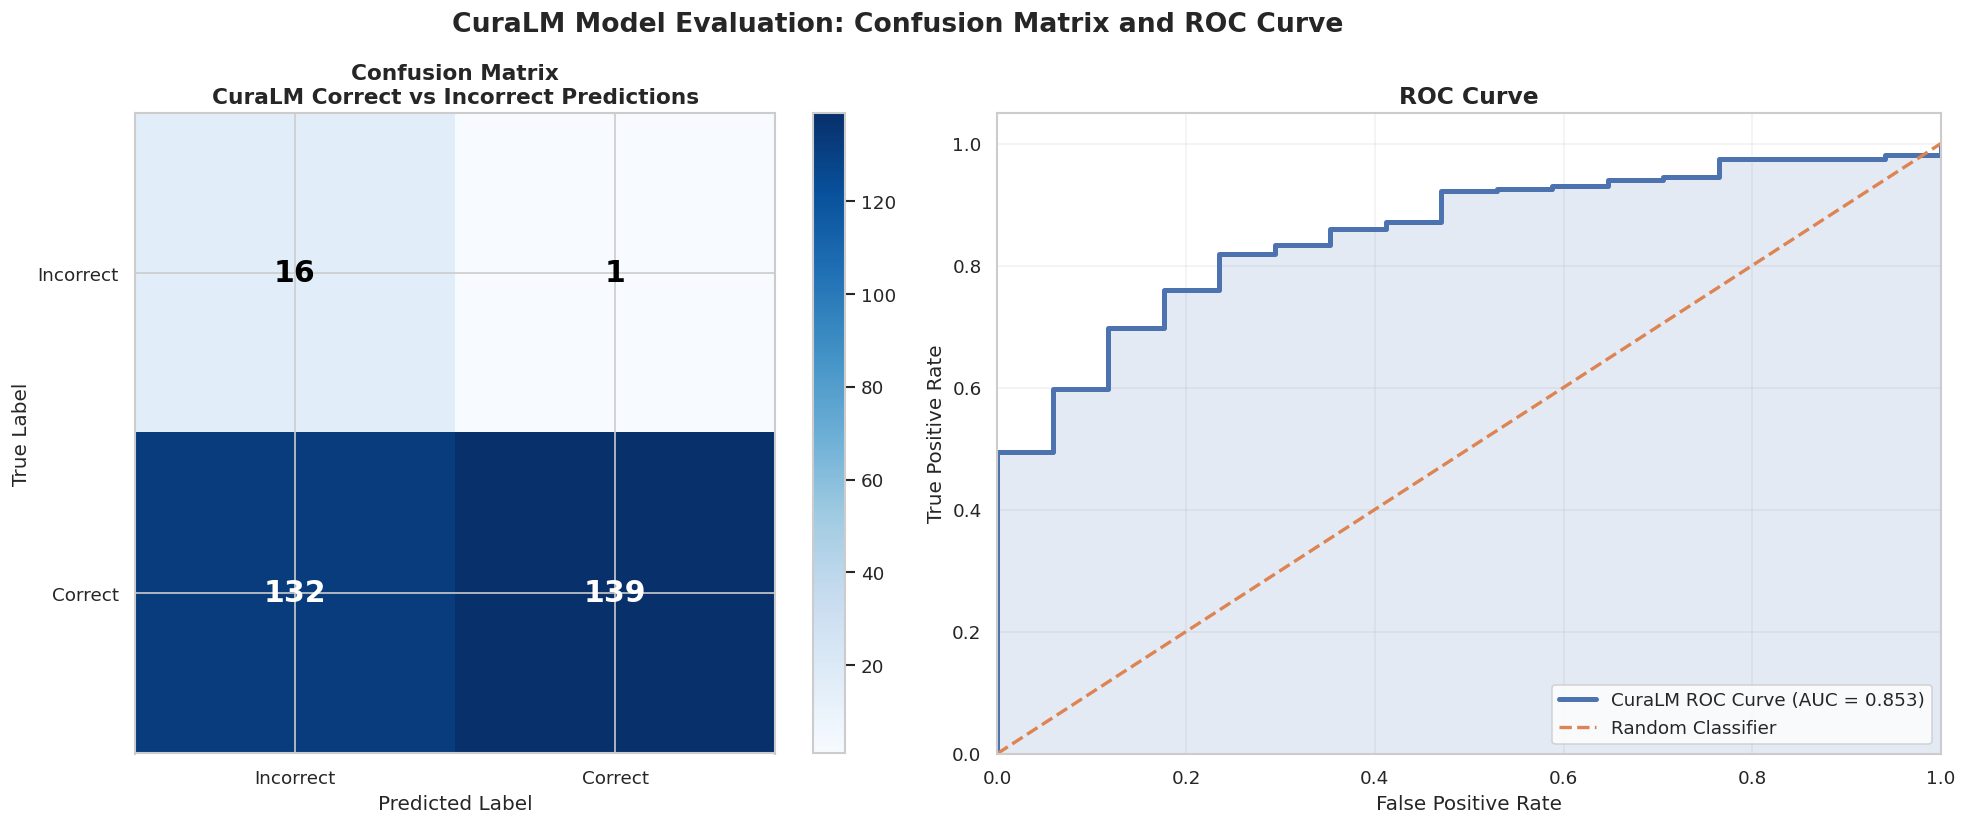

Saved plot at: /content/curalm_required_plots/confusion_matrix_and_professional_roc_curve.png


In [49]:

# Confusion Matrix + Professional ROC Curve


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, roc_curve, auc

SAVE_DIR = "/content/curalm_required_plots"
os.makedirs(SAVE_DIR, exist_ok=True)


# Check required dataframes

if "detail_results_df" not in globals():
    raise RuntimeError("detail_results_df not found. Run Cell 42 and Cell 43 first.")

if "cond_results_df" not in globals():
    raise RuntimeError("cond_results_df not found. Run Cell 42 and Cell 43 first.")

if len(detail_results_df) == 0:
    raise RuntimeError("detail_results_df is empty.")

if len(cond_results_df) == 0:
    raise RuntimeError("cond_results_df is empty.")



# Prepare evaluation dataframe


threshold = 0.90

detail_eval = pd.DataFrame({
    "task": "Drug Details",
    "true_label": detail_results_df["generic_em"].astype(int),
    "score": detail_results_df["bert_ans_f1"].astype(float),
})

condition_eval = pd.DataFrame({
    "task": "Condition to Top Drugs",
    "true_label": cond_results_df["drug_hit"].astype(int),
    "score": cond_results_df["answer_f1"].astype(float),
})

eval_df = pd.concat([detail_eval, condition_eval], ignore_index=True)
eval_df = eval_df.dropna(subset=["true_label", "score"]).copy()

eval_df["pred_label"] = (eval_df["score"] >= threshold).astype(int)


# Create figure


fig, axes = plt.subplots(1, 2, figsize=(18, 7))


# Plot 1: Confusion Matrix

cm = confusion_matrix(
    eval_df["true_label"],
    eval_df["pred_label"],
    labels=[0, 1]
)

label_names = ["Incorrect", "Correct"]

im = axes[0].imshow(cm, cmap="Blues")

axes[0].set_title(
    "Confusion Matrix\nCuraLM Correct vs Incorrect Predictions",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(label_names)

axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(label_names)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        value = cm[i, j]
        axes[0].text(
            j,
            i,
            str(value),
            ha="center",
            va="center",
            fontsize=18,
            fontweight="bold",
            color="white" if value > cm.max() / 2 else "black"
        )

fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)



# ROC Curve


y_true = eval_df["true_label"].astype(int).values
y_score = eval_df["score"].astype(float).values

if len(np.unique(y_true)) < 2:
    axes[1].text(
        0.5,
        0.5,
        "ROC Curve cannot be plotted\nbecause only one class exists.",
        ha="center",
        va="center",
        fontsize=12,
        transform=axes[1].transAxes
    )
    axes[1].set_title("ROC Curve", fontsize=14, fontweight="bold")

else:
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    axes[1].plot(
        fpr,
        tpr,
        linewidth=3,
        drawstyle="steps-post",
        label=f"CuraLM ROC Curve (AUC = {roc_auc:.3f})"
    )

    axes[1].fill_between(
        fpr,
        tpr,
        step="post",
        alpha=0.15
    )

    axes[1].plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=2,
        label="Random Classifier"
    )

    axes[1].set_title(
        "ROC Curve",
        fontsize=14,
        fontweight="bold"
    )

    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(True, alpha=0.25)
    axes[1].legend(loc="lower right", frameon=True)


plt.suptitle(
    "CuraLM Model Evaluation: Confusion Matrix and ROC Curve",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plot_path = os.path.join(SAVE_DIR, "confusion_matrix_and_professional_roc_curve.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved plot at:", plot_path)